In [1]:
# GitHub Link: https://github.com/drylife0/21bds0193/blob/main/21BDS0193.ipynb
# Colab Link: https://colab.research.google.com/drive/1qV_dfnJmu7HHrxCv7qhkofYqoTbzSP08?usp=sharing
# Dataset: USSeatBelts
# KALASH VASANIYA
# 21BDS0193

# Step 1: Loading the Dataset, Exploring Dimensions, Summary, and Data Handling
## 1.1 Load Dataset

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
url = 'https://raw.githubusercontent.com/salemprakash/EDA/main/Data/USSeatBelts.csv'
df = pd.read_csv(url)

# Load the dataset into a pandas DataFrame
df = pd.read_csv(url)

# Display the first few rows to verify successful load
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,rownames,state,year,miles,fatalities,seatbelt,speed65,speed70,drinkage,alcohol,income,age,enforce
0,1,AK,1983,3358,0.044669,NaN,no,no,yes,no,17973,28.234966,no
1,2,AK,1984,3589,0.037336,NaN,no,no,yes,no,18093,28.343542,no
2,3,AK,1985,3840,0.033073,NaN,no,no,yes,no,18925,28.372816,no
3,4,AK,1986,4008,0.025200,NaN,no,no,yes,no,18466,28.396652,no
4,5,AK,1987,3900,0.019487,NaN,no,no,yes,no,18021,28.453251,no


## 1.2 Explore Dimensions and Summary

In [3]:
# Check the shape and columns of the dataset
print("Dataset shape:", df.shape)
print("Dataset columns:", df.columns.tolist())

# Get basic information about the dataset
print("\nDataset Info:")
df.info()

# Summary statistics for numerical features
print("\nSummary Statistics:")
display(df.describe())

Dataset shape: (765, 13)
Dataset columns: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    object 
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    object 
 7   speed70     765 non-null    object 
 8   drinkage    765 non-null    object 
 9   alcohol     765 non-null    object 
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 77.8+ KB

Summary Statistics:


,rownames,year,miles,fatalities,seatbelt,income,age
count,765.000000,765.00000,765.000000,765.000000,556.000000,765.000000,765.000000
mean,383.000000,1990.00000,41447.734641,0.021490,0.528852,17992.586928,35.137194
std,220.980768,4.32332,43961.990037,0.006171,0.170186,4811.459296,1.698131
min,1.000000,1983.00000,3099.000000,0.008327,0.060000,8372.000000,28.234966
25%,192.000000,1986.00000,11401.000000,0.017341,0.420000,14266.000000,34.387501
50%,383.000000,1990.00000,30319.000000,0.021199,0.550000,17624.000000,35.391766
75%,574.000000,1994.00000,52312.000000,0.024774,0.650000,21080.000000,36.130787
max,765.000000,1997.00000,285612.000000,0.045470,0.870000,35863.000000,39.169582


## 1.3 Data Handling: Check and fill missing values in numeric columns with median and non-numeric columns with mode.

In [4]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
rownames        0
state           0
year            0
miles           0
fatalities      0
seatbelt      209
speed65         0
speed70         0
drinkage        0
alcohol         0
income          0
age             0
enforce         0
dtype: int64


# Step 2: Data Cleaning and Handling
## 2.1 Removing Duplicates

In [5]:
# Depending on the dataset, you may choose to fill or drop missing values.
# Here, we drop any rows with missing values.
df_clean = df.copy()
df_clean.dropna(inplace=True)
print("\nShape after dropping missing values:", df_clean.shape)


Shape after dropping missing values: (556, 13)


## 2.2 Plot distributions for numerical columns

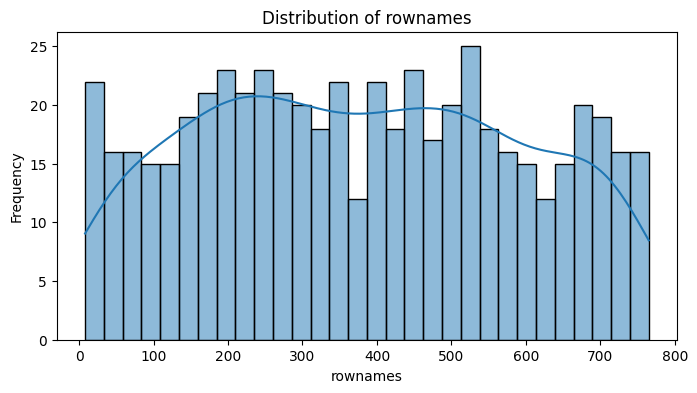

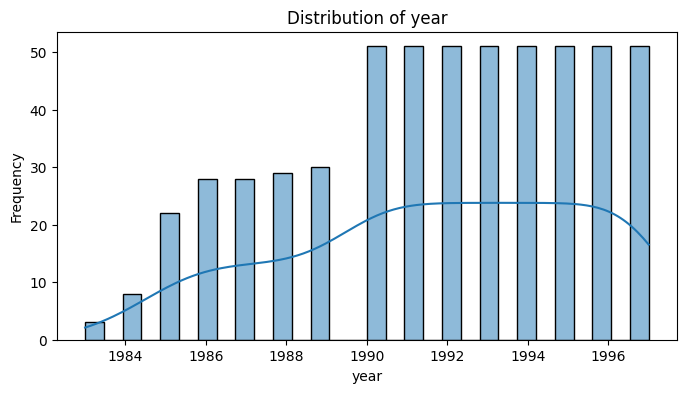

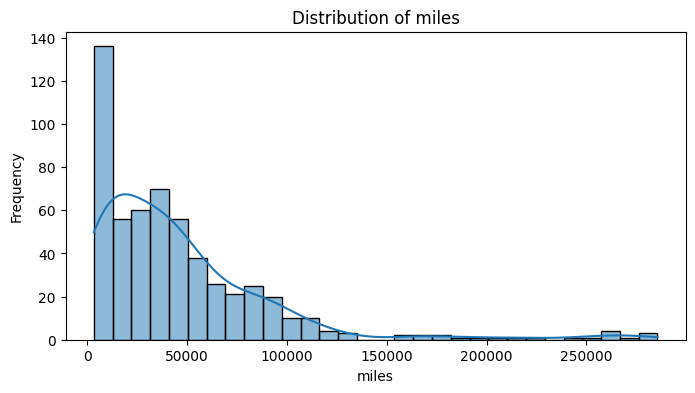

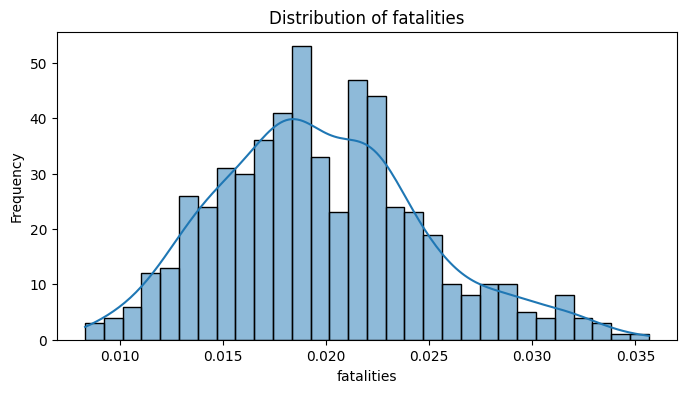

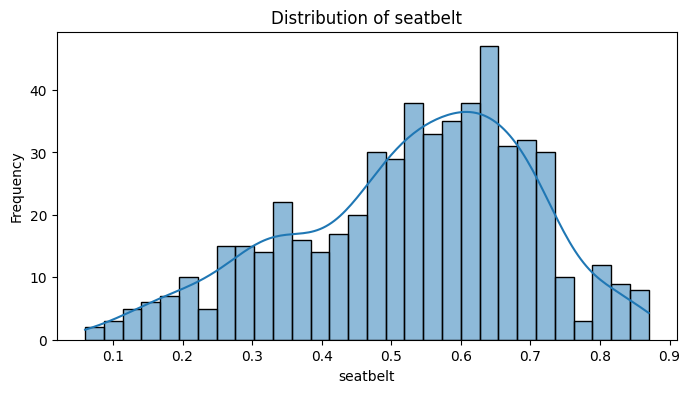

...

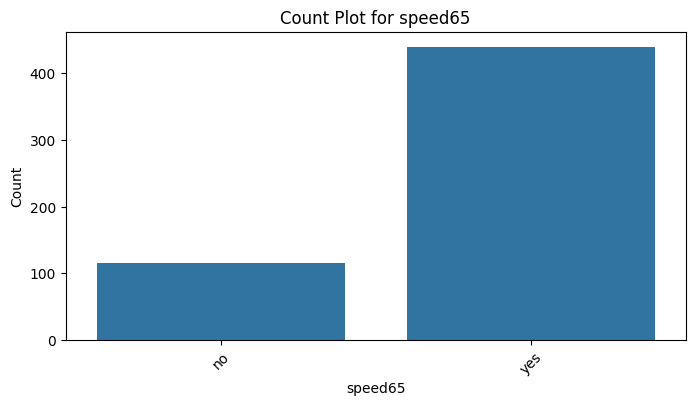

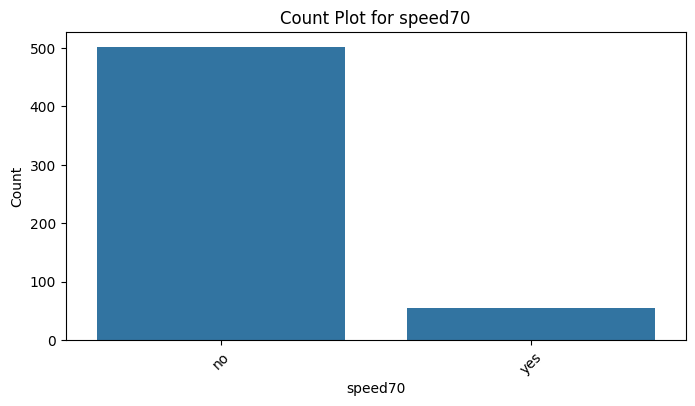

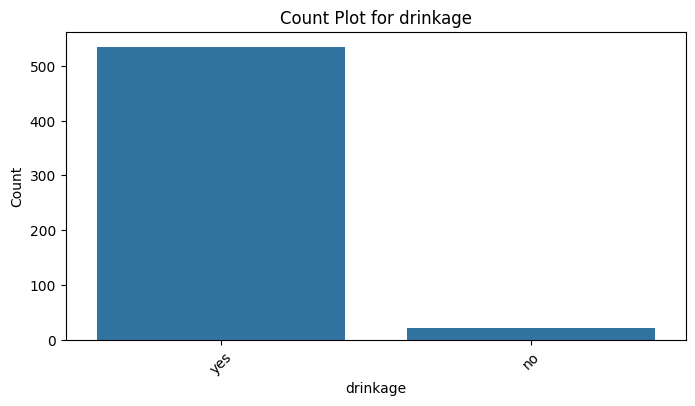

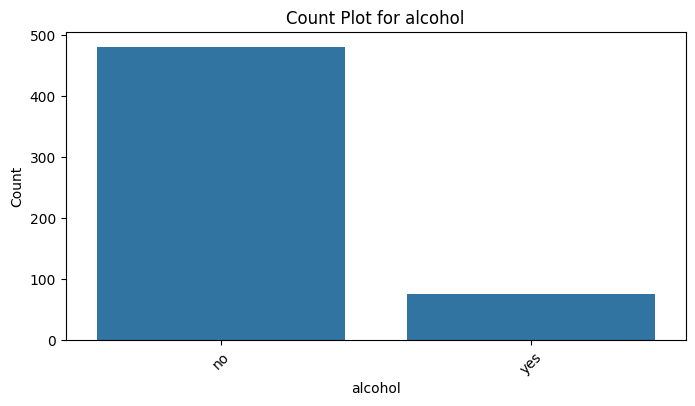

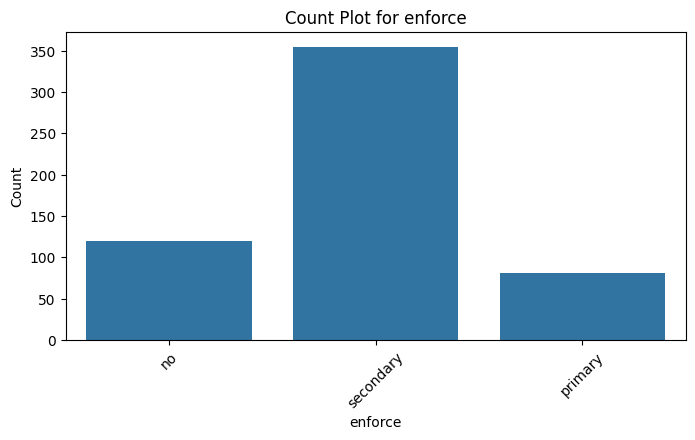

In [6]:
# Plot distributions for numerical columns
numeric_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    plt.figure(figsize=(8,4))
    sns.histplot(df_clean[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

# Plot count plots for categorical columns (if any exist)
categorical_cols = df_clean.select_dtypes(include=['object']).columns
if len(categorical_cols) > 0:
    for col in categorical_cols:
        plt.figure(figsize=(8,4))
        sns.countplot(x=col, data=df_clean)
        plt.title(f"Count Plot for {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=45)
        plt.show()
else:
    print("No categorical columns found for count plots.")

## 2.3 Bivariate Analysis

Generating pairplot for numeric features...


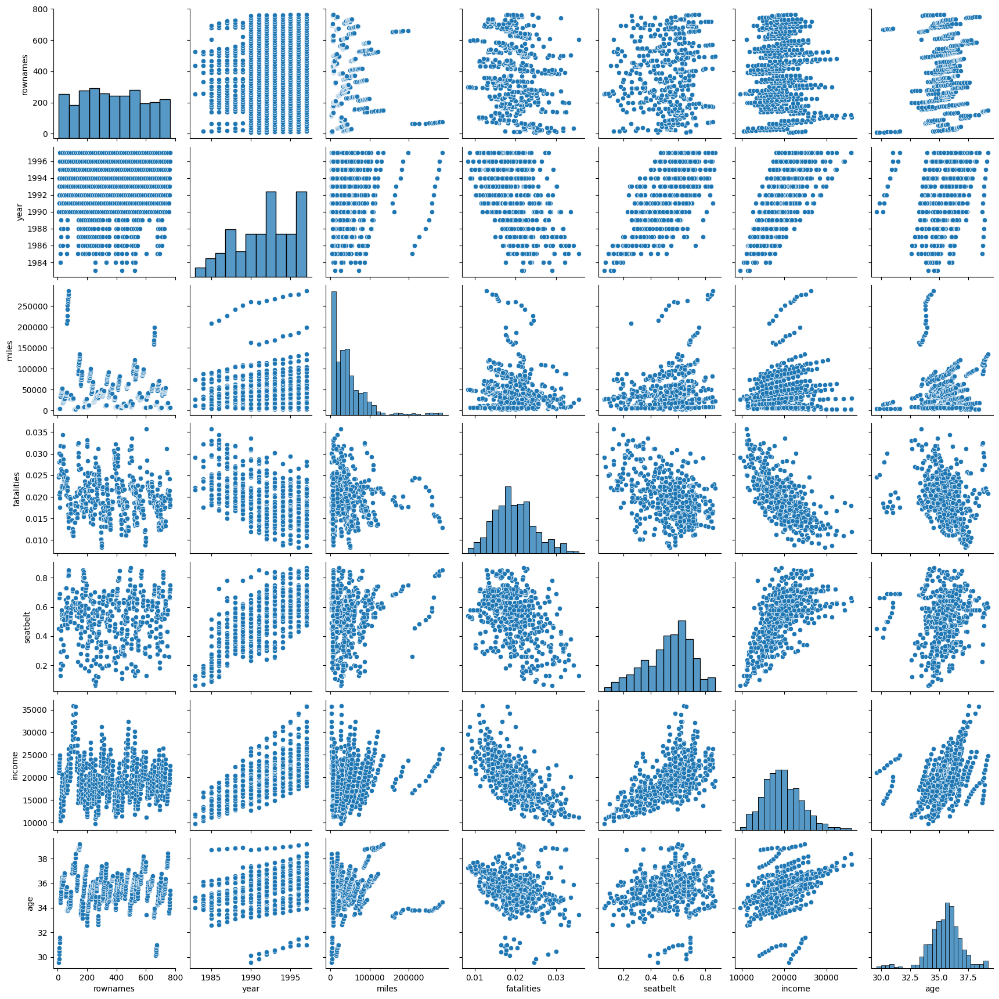

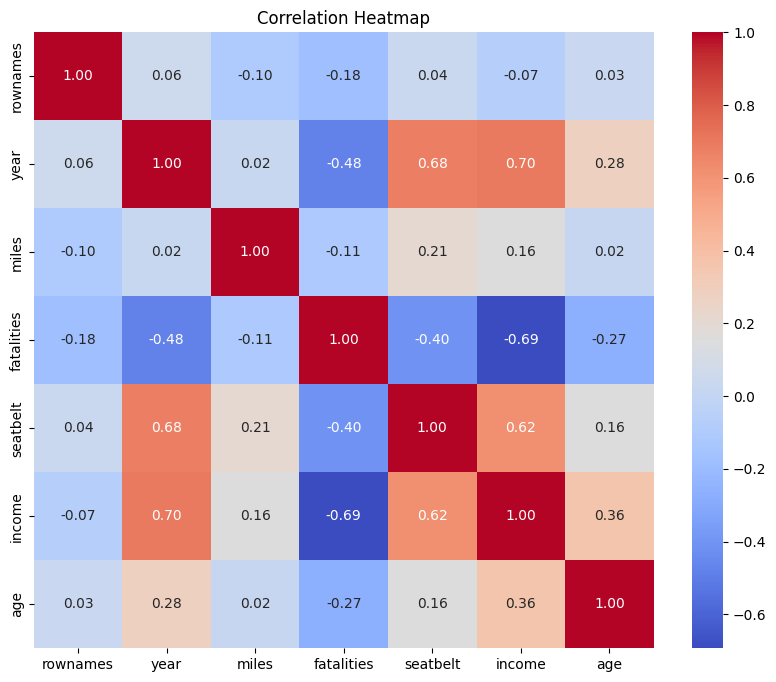

In [7]:
# Pairplot for all numeric features
print("Generating pairplot for numeric features...")
sns.pairplot(df_clean)
plt.show()

# Correlation heatmap
plt.figure(figsize=(10,8))
corr_matrix = df_clean.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## 2.4 Multivariate Analysis

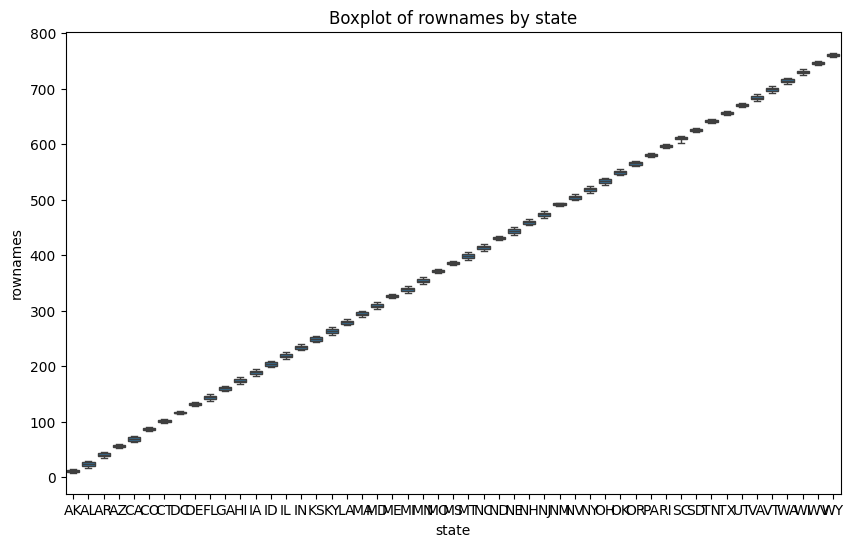

Generating PairGrid visualization...


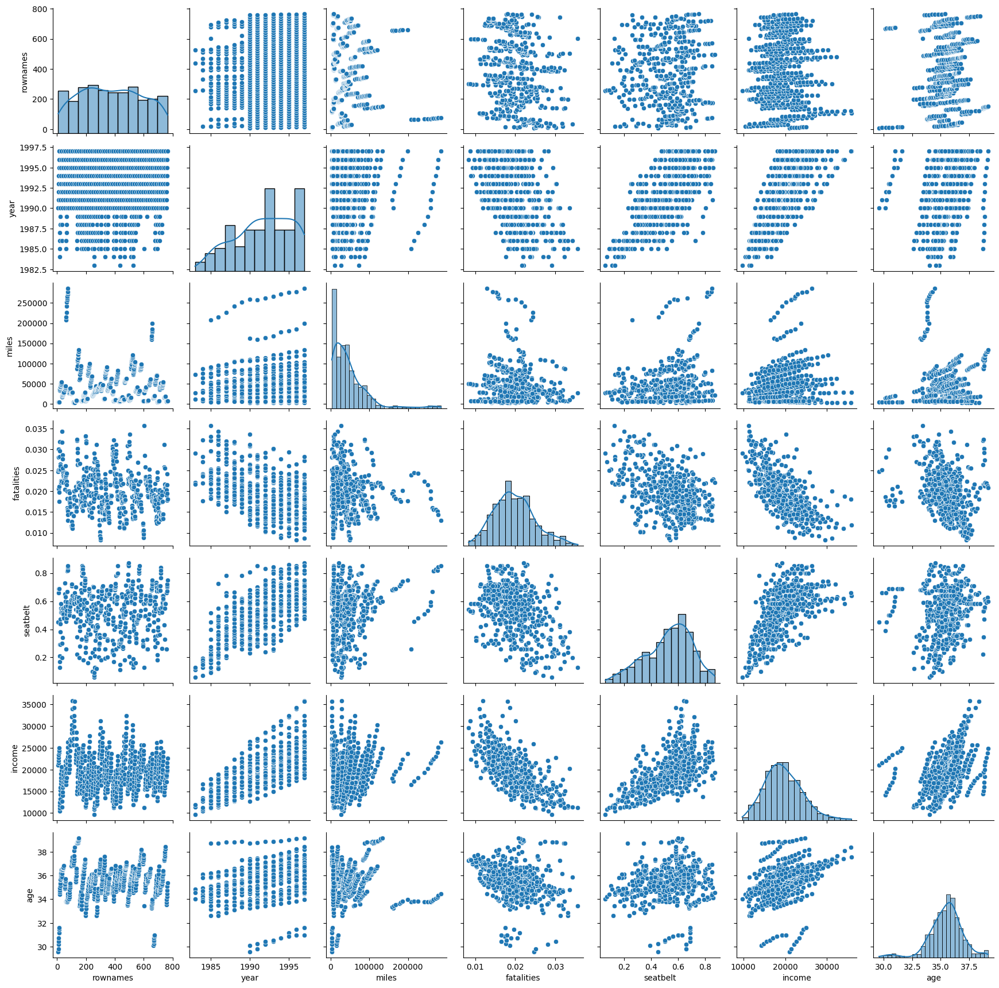

Explained Variance Ratio by the 2 principal components: [0.42572804 0.16322849]


<ipython-input-8-fb202cdc16ec>:46: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x='PCA1', y='PCA2', data=pca_df, palette="viridis")


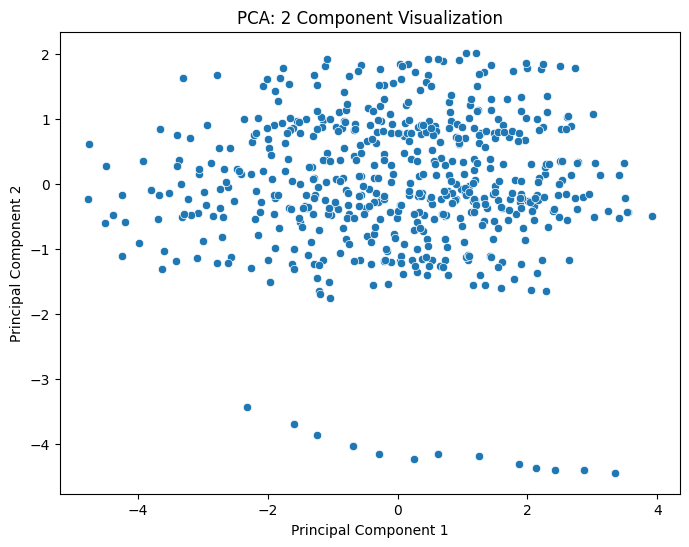

In [8]:
# Example: If a categorical column exists, plot boxplots for one numeric variable grouped by the categorical column.
# Define categorical_cols and numeric_cols before using them
categorical_cols = df_clean.select_dtypes(include=['object']).columns
numeric_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns

if len(categorical_cols) > 0 and len(numeric_cols) > 0:
    cat_col = categorical_cols[0]
    num_col = numeric_cols[0]
    plt.figure(figsize=(10,6))
    sns.boxplot(x=cat_col, y=num_col, data=df_clean)
    plt.title(f"Boxplot of {num_col} by {cat_col}")
    plt.xlabel(cat_col)
    plt.ylabel(num_col)
    plt.show()
else:
    print("Skipping boxplot by category due to lack of categorical/numeric columns.")

# Advanced PairGrid visualization
print("Generating PairGrid visualization...")
g = sns.PairGrid(df_clean)
g.map_diag(sns.histplot, kde=True)
g.map_offdiag(sns.scatterplot)
plt.show()

# Principal Component Analysis (PCA)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Select only numeric columns for PCA
data_numeric = df_clean[numeric_cols]

# Standardize the numeric data
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_numeric)

# Apply PCA to reduce dimensions to 2 for visualization purposes
pca = PCA(n_components=2)
pca_components = pca.fit_transform(data_scaled)

# Create a DataFrame with the PCA results
pca_df = pd.DataFrame(data=pca_components, columns=['PCA1', 'PCA2'])
print("Explained Variance Ratio by the 2 principal components:", pca.explained_variance_ratio_)

# Scatter plot of the two principal components
plt.figure(figsize=(8,6))
sns.scatterplot(x='PCA1', y='PCA2', data=pca_df, palette="viridis")
plt.title("PCA: 2 Component Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# Step 3: Univariate Analysis
## 3.1 Histogram

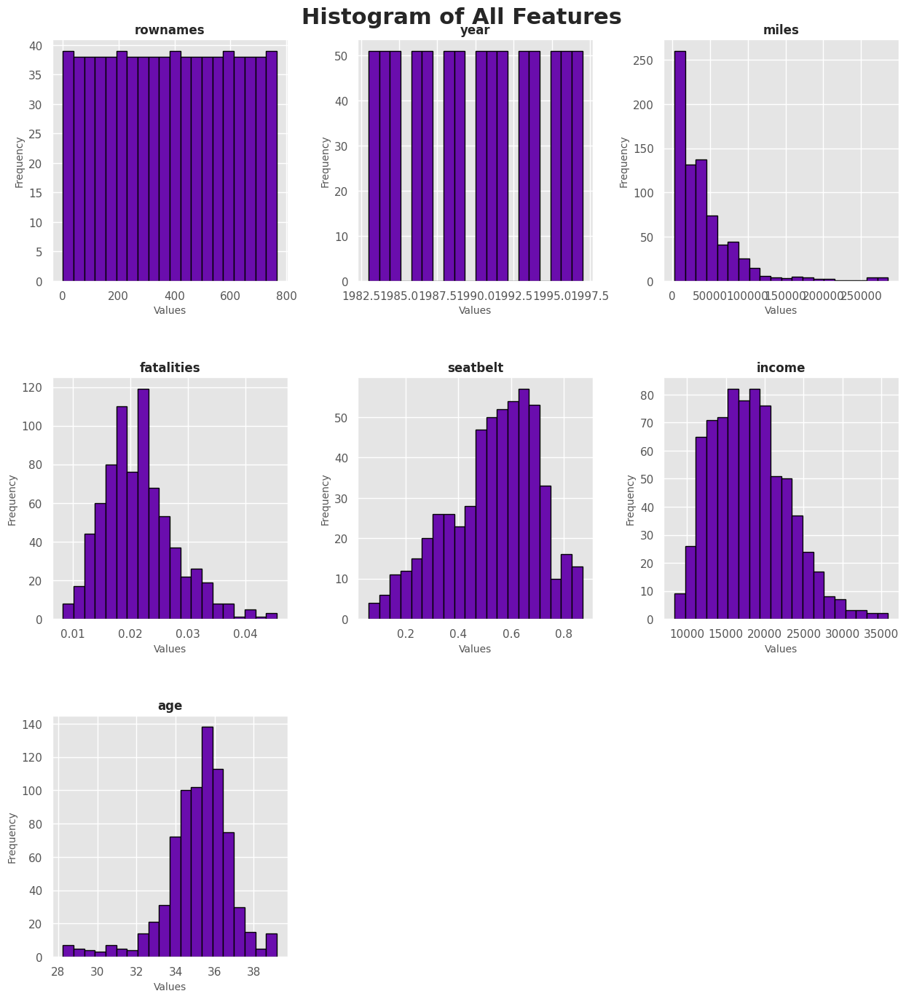

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style and palette
sns.set(style="whitegrid")
plt.style.use('ggplot')

color = '#6a0dad'

# Select only numeric columns
df_numeric = df.select_dtypes(include=['float64', 'int64'])

# Calculate number of rows needed based on the number of features
num_features = len(df_numeric.columns)
num_cols = 3  # Number of columns in the subplot grid
num_rows = (num_features // num_cols) + (num_features % num_cols > 0)

# Create subplots
fig, axes = plt.subplots(nrows=num_rows, ncols=num_cols, figsize=(15, 5 * num_rows))
axes = axes.flatten()  # Flatten the axes array for easy iteration

# Plot each feature's histogram
for i, column in enumerate(df_numeric.columns):
    ax = axes[i]
    df_numeric[column].plot(kind='hist', ax=ax, bins=20, color=color, edgecolor='black', linewidth=1.0)
    ax.set_title(column, fontsize=12, weight='bold')
    ax.set_xlabel('Values', fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)

# Remove any unused subplots (if the grid is larger than the number of plots)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Histogram of All Features', fontsize=22, weight='bold')
plt.subplots_adjust(top=0.95, hspace=0.4, wspace=0.3)
plt.show()


## 3.2 Density Plot for seatbelt

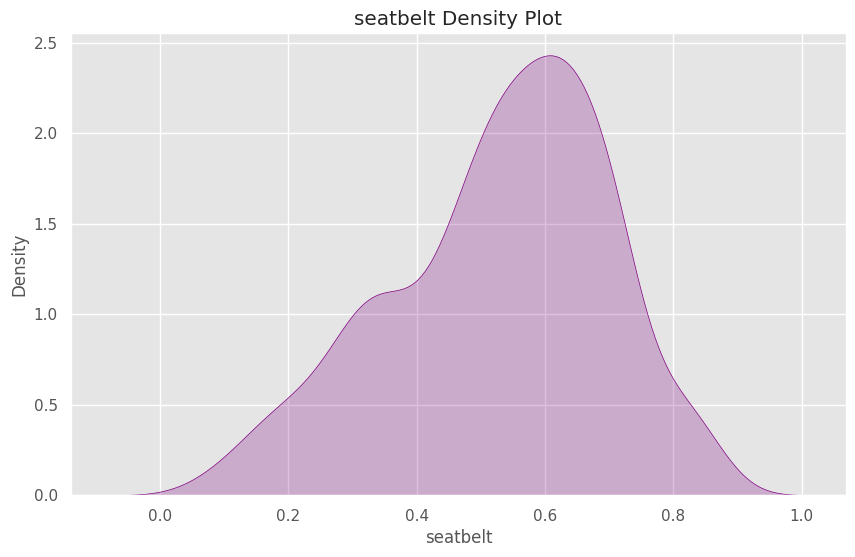

In [10]:
plt.figure(figsize=(10, 6))
sns.kdeplot(df['seatbelt'], color='purple', fill=True)
plt.title("seatbelt Density Plot")
plt.xlabel("seatbelt")
plt.ylabel("Density")
plt.show()

## 3.3 Box Plot for seatbelt

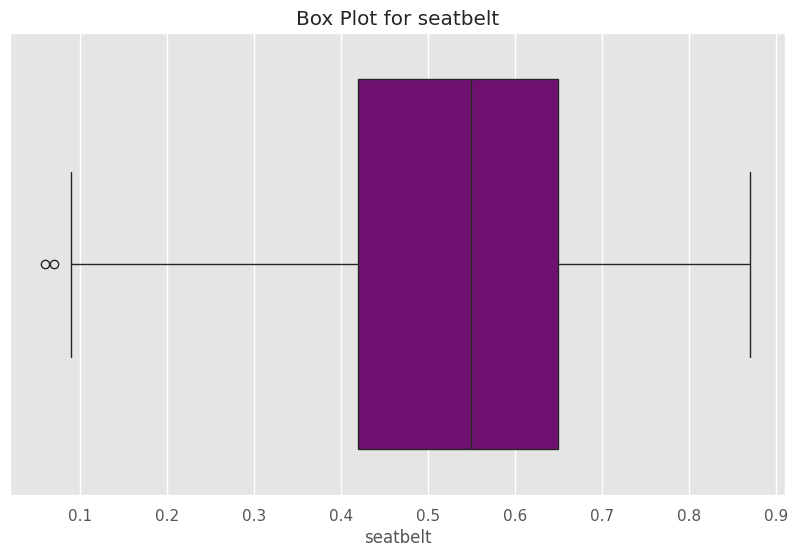

In [11]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['seatbelt'], color='purple')
plt.title("Box Plot for seatbelt")
plt.xlabel("seatbelt")
plt.show()

## 3.4 Bar Plot for seatbelt

<ipython-input-12-23f9bf3be942>:14: UserWarning: 
The palette list has fewer values (2) than needed (245) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(x='seatbelt', hue='seatbelt', data=df, palette=colors, width=0.4)


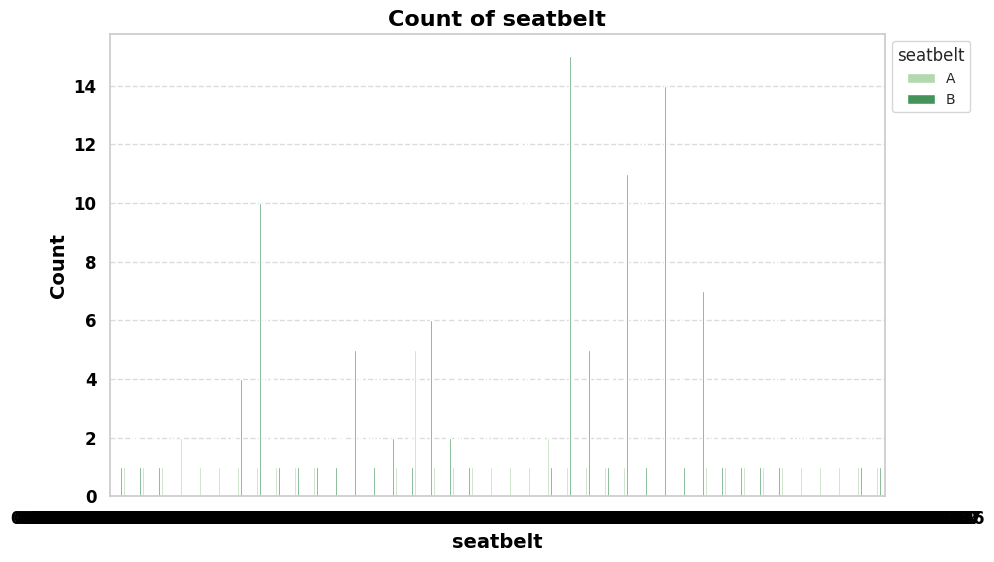

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn theme for a clean plot style
sns.set_theme(style="whitegrid")

# Create the figure and size
plt.figure(figsize=(10, 6))

# Use a green color palette (for example, "Greens") with only 2 colors
colors = sns.color_palette("Greens", n_colors=2)

# Create the count plot, using hue to define the categories
sns.countplot(x='seatbelt', hue='seatbelt', data=df, palette=colors, width=0.4)

# Set the title with bold font
plt.title("Count of seatbelt", fontsize=16, fontweight='bold', color='black')

# Customize the x and y axis labels
plt.xlabel("seatbelt", fontsize=14, color='black', fontweight='bold')
plt.ylabel("Count", fontsize=14, color='black', fontweight='bold')

# Customize tick parameters for a clean look
plt.xticks(fontsize=12, color='black', fontweight='bold')
plt.yticks(fontsize=12, color='black', fontweight='bold')

# Add gridlines for better readability with dashed style
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add a legend outside the plot area
plt.legend(title='seatbelt', labels=['A', 'B'], loc='upper left', fontsize=10, bbox_to_anchor=(1, 1))

# Show the plot
plt.show()

## 3.5 Pie Plot for seatbelt

<ipython-input-13-9f2dd9d0916e>:40: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


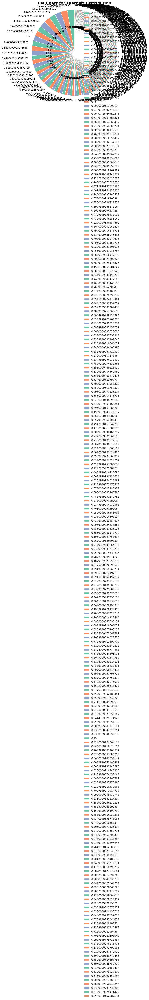

In [13]:
import matplotlib.pyplot as plt

# Count the occurrences of each seatbelt type
seatbelt_counts = df['seatbelt'].value_counts()

# Get the unique seatbelt types as labels
labels = seatbelt_counts.index.tolist()  # Get labels from the index

# Create the figure with a balanced size
plt.figure(figsize=(8, 8))

# Use a custom color palette (you can modify these colors as needed)
colors = ['#66c2a5', '#fc8d62', '#8da0cb']  # Soft green, soft orange, and soft blue

# Create the pie chart with adjusted radius
wedges, texts, autotexts = plt.pie(
    seatbelt_counts,
    labels=labels,  # Use the generated labels
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    shadow=False,  # No shadow for a flat look
    radius=0.8  # Adjust the radius to make it smaller
)

# Set the title with appropriate font size and style
plt.title("Pie Chart for seatbelt Distribution", fontsize=18, fontweight='bold', color='black')
plt.axis('equal')  # Equal aspect ratio ensures pie is drawn as a circle.

# Customize text colors to be consistent
for text in texts:
    text.set_color('black')  # Set all text to black
for text in autotexts:
    text.set_color('black')  # Set percentage text to black

# Create a legend
plt.legend(wedges, labels, title="seatbelt", loc="upper right", fontsize=12, frameon=False)

# Improve layout and ensure everything fits well
plt.tight_layout()

# Show the pie chart
plt.show()

## 3.6 Dotplot for seatbelt

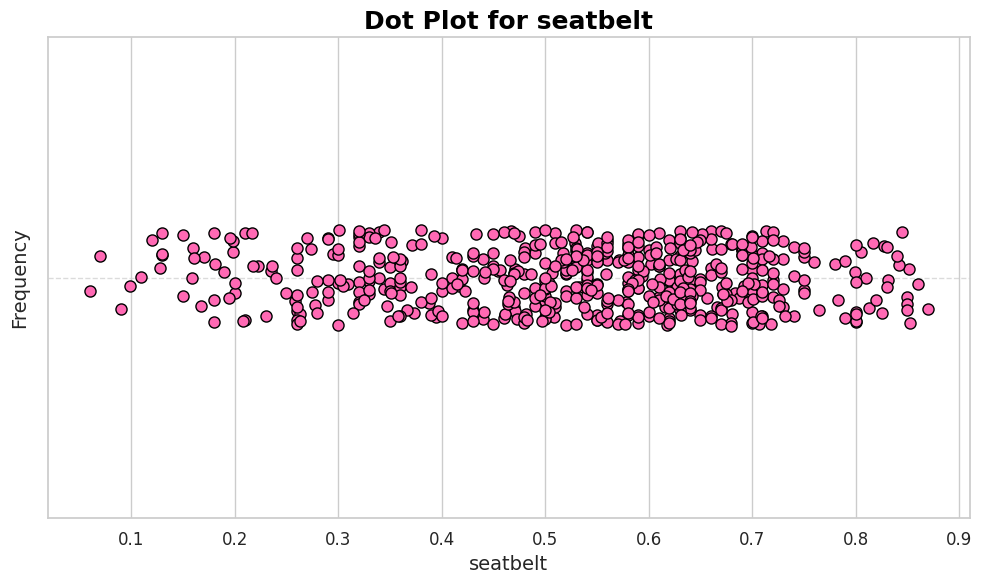

In [14]:
plt.figure(figsize=(10, 6))

# Dot plot for 'area_mean' (or replace with another numerical column)
sns.stripplot(x='seatbelt', data=df, color='#FF69B4', size=8, jitter=True, edgecolor='black', linewidth=1)

plt.title("Dot Plot for seatbelt", fontsize=18, fontweight='bold', color='black')
plt.xlabel("seatbelt", fontsize=14)
plt.ylabel("Frequency", fontsize=14)

# Customize ticks and labels
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add grid lines for better readability
plt.tight_layout()
plt.show()


## 3.7 Boxplot for seatbelt

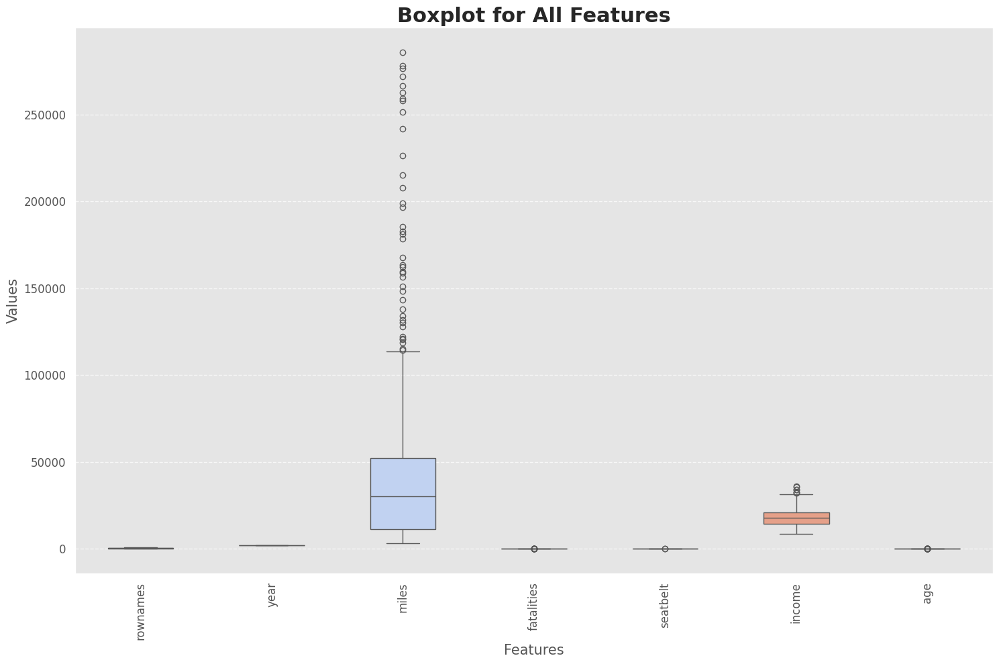

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style and palette
sns.set(style="whitegrid")
plt.style.use('ggplot')

# Select only numeric columns
df_numeric = df.select_dtypes(include=['float64', 'int64'])

# Define a color palette with diverse colors for clarity
palette = sns.color_palette("coolwarm", n_colors=len(df_numeric.columns))

# Create the boxplot
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_numeric, palette=palette, width=0.5)

# Enhance plot aesthetics
plt.title('Boxplot for All Features', fontsize=22, weight='bold')
plt.xlabel('Features', fontsize=15)
plt.ylabel('Values', fontsize=15)
plt.xticks(rotation=90, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)  # grid lines for better readability

# Show plot
plt.tight_layout()
plt.show()


# Module 2

## 6.1 Merging Data

In [16]:
# Example: Creating a secondary dataframe to merge (based on 'seatbelt')
df_merge = df[['state', 'seatbelt']]
df_merged = pd.merge(df, df_merge, on='state')

# View the merged dataframe
df_merged.head()

,rownames,state,year,miles,fatalities,seatbelt_x,speed65,speed70,drinkage,alcohol,income,age,enforce,seatbelt_y
0,1,AK,1983,3358,0.044669,NaN,no,no,yes,no,17973,28.234966,no,NaN
1,1,AK,1983,3358,0.044669,NaN,no,no,yes,no,17973,28.234966,no,NaN
2,1,AK,1983,3358,0.044669,NaN,no,no,yes,no,17973,28.234966,no,NaN
3,1,AK,1983,3358,0.044669,NaN,no,no,yes,no,17973,28.234966,no,NaN
4,1,AK,1983,3358,0.044669,NaN,no,no,yes,no,17973,28.234966,no,NaN


## 6.2 Reshaping with Hierarchical Indexing

In [17]:
# Setting a hierarchical index based on seatbelt and another existing numeric column (e.g., 'miles')
df.set_index(['seatbelt', 'miles'], inplace=True)
df.head()

# Resetting the index back
df.reset_index(inplace=True)
df.head()

,seatbelt,miles,rownames,state,year,fatalities,speed65,speed70,drinkage,alcohol,income,age,enforce
0,NaN,3358,1,AK,1983,0.044669,no,no,yes,no,17973,28.234966,no
1,NaN,3589,2,AK,1984,0.037336,no,no,yes,no,18093,28.343542,no
2,NaN,3840,3,AK,1985,0.033073,no,no,yes,no,18925,28.372816,no
3,NaN,4008,4,AK,1986,0.025200,no,no,yes,no,18466,28.396652,no
4,NaN,3900,5,AK,1987,0.019487,no,no,yes,no,18021,28.453251,no


## 6.3 Transformation Techniques

In [18]:
# Applying log transformation to reduce skewness
# Check if 'radius_mean' exists in the DataFrame before applying the transformation
if 'miles' in df.columns:
    df['log_miles'] = np.log(df['miles'] + 1)  # Adding 1 to avoid log(0)

    # View transformed column
    print(df[['miles', 'log_miles']].head())
else:
    print("Column 'miles' not found in the DataFrame.")

   miles  log_miles
0   3358   8.119399
1   3589   8.185907
2   3840   8.253488
3   4008   8.296297
4   3900   8.268988


## 6.4 Discretization and Binning

In [19]:
# Discretizing the 'miles' column into bins (adjusting bins based on data distribution)
# Get the range of 'miles' values
min_miles = df['miles'].min()
max_miles = df['miles'].max()

# Define bins based on the range - consider quantiles for better distribution
bins = [min_miles,  df['miles'].quantile(0.25), df['miles'].quantile(0.5), df['miles'].quantile(0.75), max_miles]

labels = ['Small', 'Medium', 'Large', 'XLarge']  # Adjusted labels for new bins
df['radius_bin'] = pd.cut(df['miles'], bins=bins, labels=labels, include_lowest=True, duplicates='drop')

# View the binned column
df[['miles', 'radius_bin']].head()

,miles,radius_bin
0,3358,Small
1,3589,Small
2,3840,Small
3,4008,Small
4,3900,Small


# Module 3
## 7.1 Create a Simulated Time Index

In [20]:
# Simulate a time index
df['time'] = pd.Series(range(len(df)))

## 7.2 Check for Missing Values

In [21]:
# Check for missing values
missing_values = df.isnull().sum()
print("Missing Values:\n", missing_values)

Missing Values:
 seatbelt      209
miles           0
rownames        0
state           0
year            0
fatalities      0
speed65         0
speed70         0
drinkage        0
alcohol         0
income          0
age             0
enforce         0
log_miles       0
radius_bin      0
time            0
dtype: int64


## 7.3 Plot the Time Series

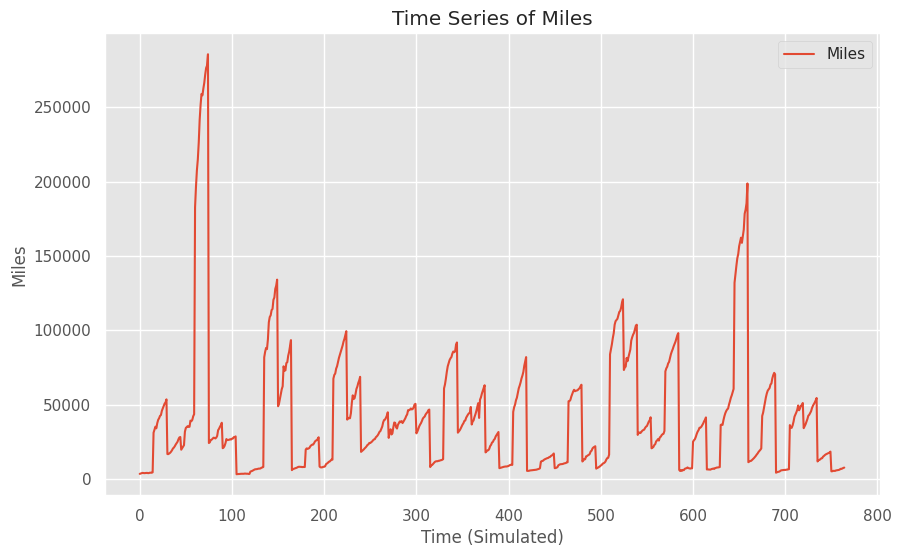

In [22]:
import matplotlib.pyplot as plt

# Plot the time series of Miles
plt.figure(figsize=(10, 6))
plt.plot(df['time'], df['miles'], label='Miles')
plt.title("Time Series of Miles")
plt.xlabel("Time (Simulated)")
plt.ylabel("Miles")
plt.legend()
plt.show()

## 7.4 Decompose the Dataset

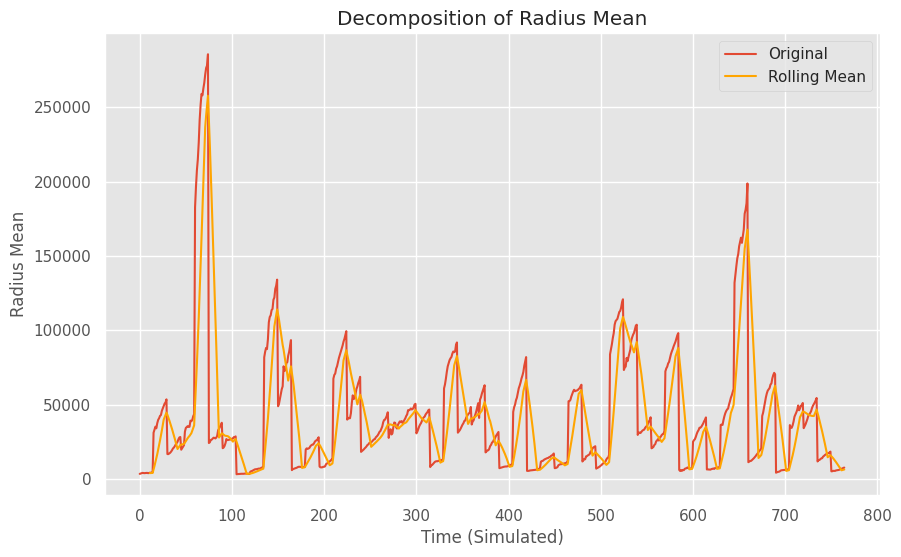

In [23]:
# Calculate rolling mean
df['rolling_mean'] = df['miles'].rolling(window=12).mean()

# Plot original and rolling mean
plt.figure(figsize=(10, 6))
plt.plot(df['time'], df['miles'], label='Original')
plt.plot(df['time'], df['rolling_mean'], label='Rolling Mean', color='orange')
plt.title("Decomposition of Radius Mean")
plt.xlabel("Time (Simulated)")
plt.ylabel("Radius Mean")
plt.legend()
plt.show()

## 7.5 Make the Dataset Stationary

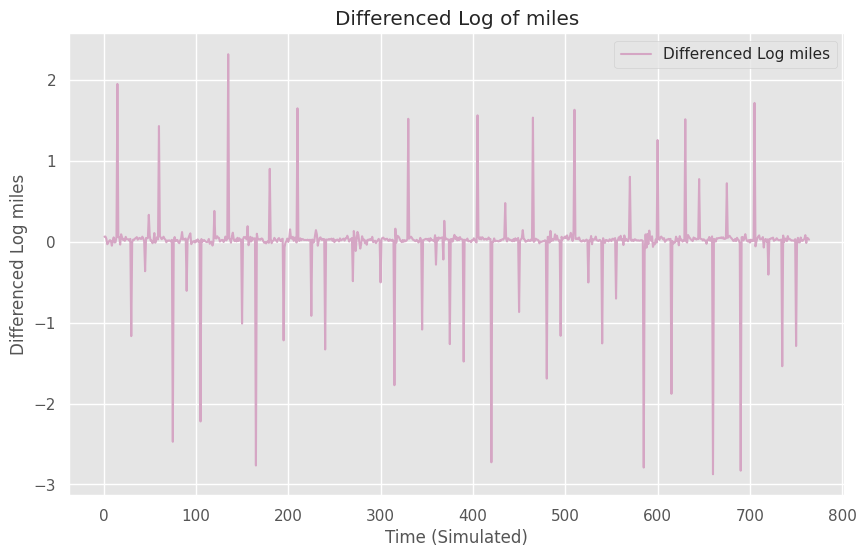

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# Check if 'miles' exists in the DataFrame
if 'miles' in df.columns:
    # Log transformation
    df['log_miles'] = np.log(df['miles'])

    # Differencing to make it stationary
    df['diff_log_miles'] = df['log_miles'].diff()

    # Plotting the differenced series
    plt.figure(figsize=(10, 6))
    plt.plot(df['time'], df['diff_log_miles'], label='Differenced Log miles', color="#D5A6C4")
    plt.title("Differenced Log of miles")
    plt.xlabel("Time (Simulated)")
    plt.ylabel("Differenced Log miles")
    plt.legend(loc='upper right')
    plt.show()
else:
    print("Column 'miles' not found in the DataFrame.")

## 7.6 Plot Box Plot Across Categories

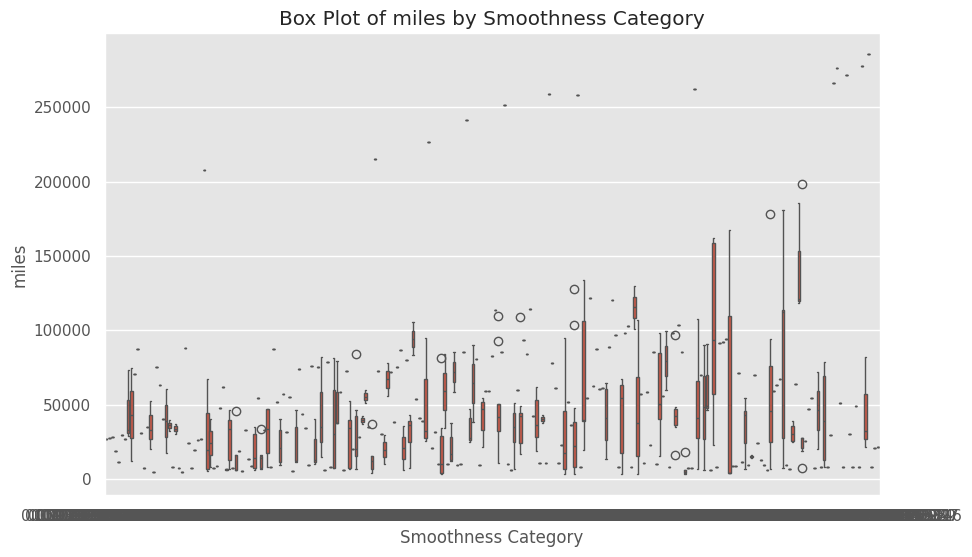

In [25]:
import seaborn as sns

# Box plot by smoothness category
plt.figure(figsize=(10, 6))
sns.boxplot(x='seatbelt', y='miles', data=df)
plt.title("Box Plot of miles by Smoothness Category")
plt.xlabel("Smoothness Category")
plt.ylabel("miles")
plt.show()

# Module 4
## 8. 1D Statistical Data Analysis
## 8.1 Measures of Central Tendency
### 8.1.1 Mean and Median

In [26]:
# Calculate Mean
# Excluding non-numeric columns ('state', 'rownames') from the mean calculation
mean_values = df[['miles', 'seatbelt', 'year']].mean()
print("Mean Values:\n", mean_values)

# Calculate Median
# Excluding non-numeric columns ('state', 'rownames') from the median calculation
median_values = df[['miles', 'seatbelt', 'year']].median()
print("\nMedian Values:\n", median_values)

# Calculate Quantiles
# Excluding non-numeric columns ('state', 'rownames') from the quantile calculation
quantiles = df[['miles', 'seatbelt', 'year']].quantile([0.25, 0.5, 0.75])
print("\nQuantiles (25%, 50%, 75%):\n", quantiles)

Mean Values:
 miles       41447.734641
seatbelt        0.528852
year         1990.000000
dtype: float64

Median Values:
 miles       30319.00
seatbelt        0.55
year         1990.00
dtype: float64

Quantiles (25%, 50%, 75%):
         miles  seatbelt    year
0.25  11401.0      0.42  1986.0
0.50  30319.0      0.55  1990.0
0.75  52312.0      0.65  1994.0


## 8.2 Measures of Dispersion

In [27]:
import scipy.stats as stats

# Define the columns to analyze - Choose existing columns from your DataFrame
columns = ['miles', 'seatbelt', 'year']  # Example: Using existing columns

# 1. Range
range_values = df[columns].max() - df[columns].min()
print("\nRange Values:\n", range_values)

# 2. Interquartile Range (IQR)
iqr_values = stats.iqr(df[columns], axis=0)
print("\nInterquartile Range (IQR):\n", iqr_values)

# 3. Standard Deviation
std_dev = df[columns].std()
print("\nStandard Deviation:\n", std_dev)

# 4. Skewness
skewness = df[columns].skew()
print("\nSkewness:\n", skewness)

# 5. Kurtosis
kurtosis = df[columns].kurt()
print("\nKurtosis:\n", kurtosis)


Range Values:
 miles       282513.00
seatbelt         0.81
year            14.00
dtype: float64

Interquartile Range (IQR):
 [4.0911e+04        nan 8.0000e+00]

Standard Deviation:
 miles       43961.990037
seatbelt        0.170186
year            4.323320
dtype: float64

Skewness:
 miles       2.611102
seatbelt   -0.469884
year        0.000000
dtype: float64

Kurtosis:
 miles       9.063223
seatbelt   -0.339125
year       -1.210781
dtype: float64


## 8.3 Frequency Distribution

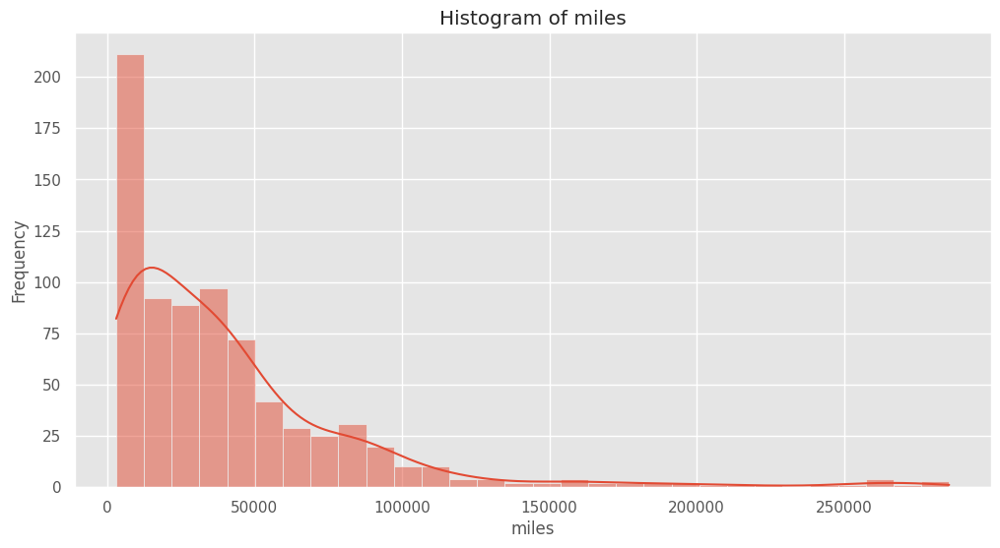

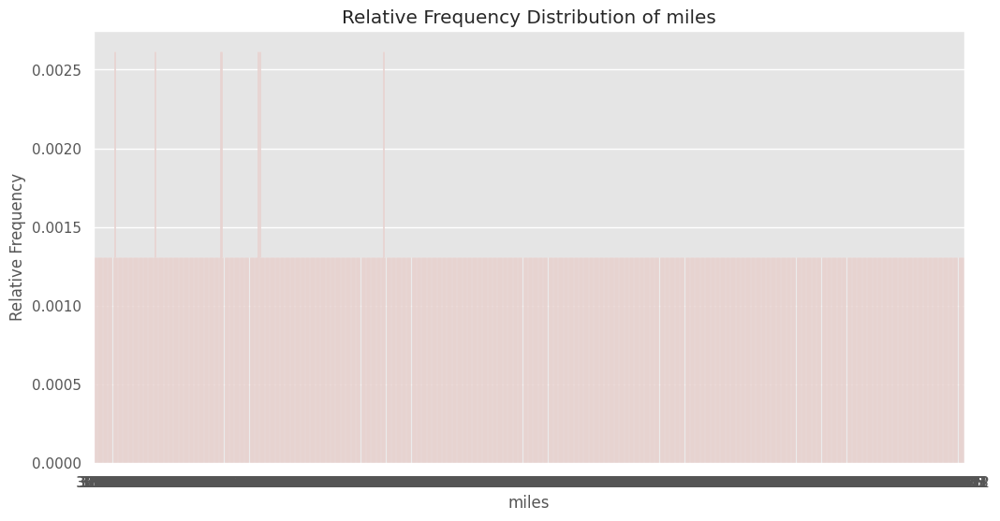

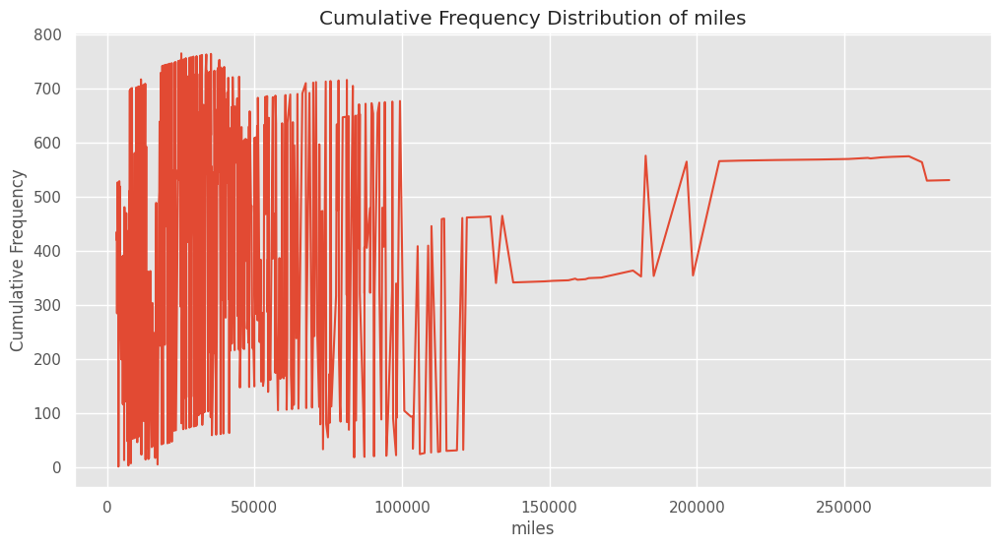

In [28]:
plt.figure(figsize=(12, 6))
sns.histplot(df['miles'], bins=30, kde=True)
plt.title("Histogram of miles")
plt.xlabel("miles")
plt.ylabel("Frequency")
plt.show()

# Relative frequency
rel_freq = df['miles'].value_counts(normalize=True)

plt.figure(figsize=(12, 6))
sns.barplot(x=rel_freq.index, y=rel_freq.values)
plt.title("Relative Frequency Distribution of miles")
plt.xlabel("miles")
plt.ylabel("Relative Frequency")
plt.show()

cumulative_freq = df['miles'].value_counts().cumsum()

plt.figure(figsize=(12, 6))
sns.lineplot(x=cumulative_freq.index, y=cumulative_freq.values)
plt.title("Cumulative Frequency Distribution of miles")
plt.xlabel("miles")
plt.ylabel("Cumulative Frequency")
plt.show()

## 8.4 Categorical Variable Analysis

   miles log_miles
0   3358       Low
1   3589       Low
2   3840       Low
3   4008       Low
4   3900       Low


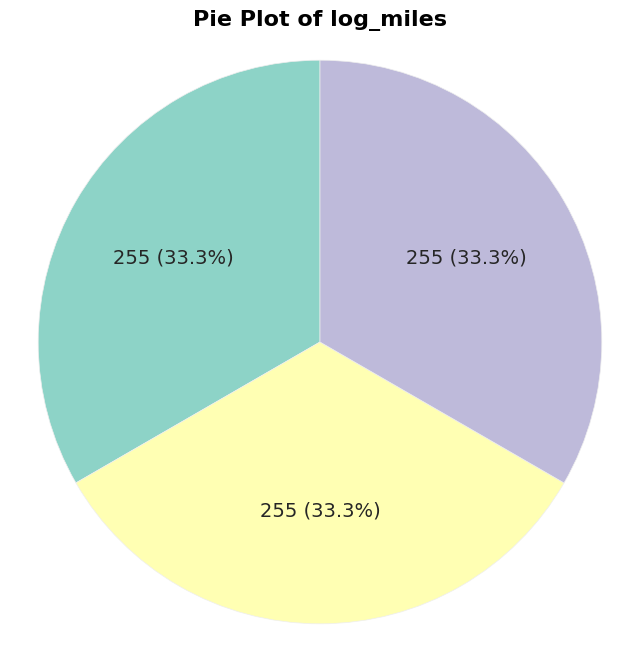

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Categorizing smoothness_mean into Low, Medium, and High
# Adjusting bins to ensure they cover the data range and avoid empty categories
df['log_miles'] = pd.cut(df['miles'],
                                   bins=pd.qcut(df['miles'], q=3, retbins=True, duplicates='drop')[1],  # Using quantiles for bins
                                   labels=['Low', 'Medium', 'High'],
                                   include_lowest=True,
                                   duplicates='drop')  # Ensuring all values are included

# Verifying the creation of the new column
print(df[['miles', 'log_miles']].head())

def func(pct, allvalues):
    absolute = int(pct / 100. * sum(allvalues))
    return f'{absolute} ({pct:.1f}%)' if pct > 5 else ''  # Show percentages only if >5%

# Create a figure for the pie chart
plt.figure(figsize=(8, 8))

# Calculate sizes for each category
sizes = df['log_miles'].value_counts()

# Use a color palette from Seaborn for a more diverse look
colors = sns.color_palette("Set3", n_colors=len(sizes))

# Create the pie chart
plt.pie(sizes,
        autopct=lambda pct: func(pct, sizes),
        startangle=90,
        colors=colors,
        textprops={'fontsize': 14})

# Title and layout settings
plt.title("Pie Plot of log_miles", fontsize=16, fontweight='bold', color='black')
plt.axis('equal')  # Equal aspect ratio ensures pie is drawn as a circle

# Show the plot
plt.show()

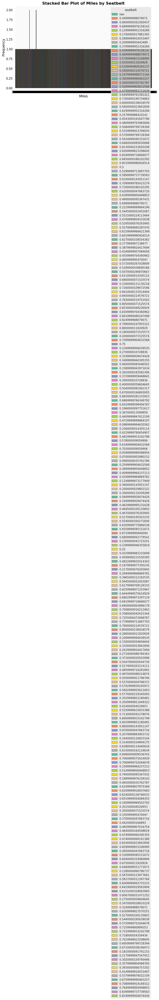

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Creating a pivot table for seatbelt by miles
pivot_table = df.groupby(['miles', 'seatbelt'], observed=True).size().unstack()

plt.figure(figsize=(10, 6))

# Use a color palette from Seaborn for a more diverse look
colors = sns.color_palette("Set2", n_colors=len(pivot_table.columns))

# Plot the stacked bar chart
pivot_table.plot(kind='bar', stacked=True, color=colors, edgecolor='black', ax=plt.gca())

# Titles and labels
plt.title("Stacked Bar Plot of Miles by Seatbelt", fontsize=16, fontweight='bold', color='black')
plt.xlabel("Miles", fontsize=14, color='black')
plt.ylabel("Frequency", fontsize=14, color='black')

# Customize ticks
plt.xticks(rotation=0, fontsize=12, color='black')
plt.yticks(fontsize=12, color='black')

# Add legend with a frame
# Get unique seatbelt values for legend labels
seatbelt_labels = df['seatbelt'].unique()
plt.legend(title='seatbelt', labels=seatbelt_labels, loc='upper right', frameon=True)

# Add grid lines for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Tight layout for better spacing
plt.tight_layout()

# Show the plot
plt.show()

# 9. Exploratory Data Analysis for Structured data - 2D Analysis
## 9.1 Create 2-Way Contingency Tables for Categorical-Categorical, Numerical-Numerical, and Categorical-Numerical Variables

In [31]:
# Import necessary libraries
import pandas as pd

# Categorical-Categorical (e.g., 'seatbelt' and binned 'miles')
categorical_categorical = pd.crosstab(df['seatbelt'], pd.cut(df['miles'], bins=3))
print("Categorical-Categorical Contingency Table:\n", categorical_categorical)

# Numerical-Numerical (e.g., binned 'age' vs binned 'miles')
numerical_numerical = pd.crosstab(pd.cut(df['age'], bins=3), pd.cut(df['miles'], bins=3))
print("\nNumerical-Numerical Contingency Table:\n", numerical_numerical)

# Categorical-Numerical (e.g., 'seatbelt' and binned 'age')
categorical_numerical = pd.crosstab(df['seatbelt'], pd.cut(df['age'], bins=3))
print("\nCategorical-Numerical Contingency Table:\n", categorical_numerical)

Categorical-Categorical Contingency Table:
 miles     (2816.487, 97270.0]  (97270.0, 191441.0]  (191441.0, 285612.0]
seatbelt                                                                
0.060                       1                    0                     0
0.070                       1                    0                     0
0.090                       1                    0                     0
0.099                       1                    0                     0
0.110                       1                    0                     0
...                       ...                  ...                   ...
0.850                       3                    0                     0
0.852                       0                    0                     1
0.853                       1                    0                     0
0.860                       1                    0                     0
0.870                       1                    0                     0

[245 r

## 9.2 Create a 3-Way Contingency Table

In [32]:
# 3-way contingency table for 'seatbelt', binned 'age', and binned 'miles'
three_way_table = pd.crosstab([df['seatbelt'], pd.cut(df['age'], bins=3)], pd.cut(df['miles'], bins=3))
print("\n3-Way Contingency Table:\n", three_way_table)


3-Way Contingency Table:
 miles                     (2816.487, 97270.0]  (97270.0, 191441.0]  \
seatbelt age                                                         
0.060    (31.88, 35.525]                    1                    0   
0.070    (31.88, 35.525]                    1                    0   
0.090    (31.88, 35.525]                    1                    0   
0.099    (31.88, 35.525]                    1                    0   
0.110    (31.88, 35.525]                    1                    0   
...                                       ...                  ...   
0.850    (35.525, 39.17]                    2                    0   
0.852    (31.88, 35.525]                    0                    0   
0.853    (31.88, 35.525]                    1                    0   
0.860    (31.88, 35.525]                    1                    0   
0.870    (31.88, 35.525]                    1                    0   

miles                     (191441.0, 285612.0]  
seatbelt age 

## 9.3 Apply Row Profile, Column Profile, Relative Frequency, and Chi-Square Test

In [33]:
import scipy.stats as stats

# Row profile and column profile for the 3-way table
row_profile = three_way_table.div(three_way_table.sum(axis=1), axis=0)
print("\nRow Profile:\n", row_profile)

col_profile = three_way_table.div(three_way_table.sum(axis=0), axis=1)
print("\nColumn Profile:\n", col_profile)

# Relative frequency
relative_frequency = three_way_table / three_way_table.sum().sum()
print("\nRelative Frequency:\n", relative_frequency)

# Chi-square test
chi2_stat, p_val, dof, ex = stats.chi2_contingency(three_way_table)
print(f"\nChi-Square Test:\nChi2 Statistic = {chi2_stat}, p-value = {p_val}")


Row Profile:
 miles                     (2816.487, 97270.0]  (97270.0, 191441.0]  \
seatbelt age                                                         
0.060    (31.88, 35.525]                  1.0                  0.0   
0.070    (31.88, 35.525]                  1.0                  0.0   
0.090    (31.88, 35.525]                  1.0                  0.0   
0.099    (31.88, 35.525]                  1.0                  0.0   
0.110    (31.88, 35.525]                  1.0                  0.0   
...                                       ...                  ...   
0.850    (35.525, 39.17]                  1.0                  0.0   
0.852    (31.88, 35.525]                  0.0                  0.0   
0.853    (31.88, 35.525]                  1.0                  0.0   
0.860    (31.88, 35.525]                  1.0                  0.0   
0.870    (31.88, 35.525]                  1.0                  0.0   

miles                     (191441.0, 285612.0]  
seatbelt age             

## 9.4 Display Scatter Plot for 2 Variables

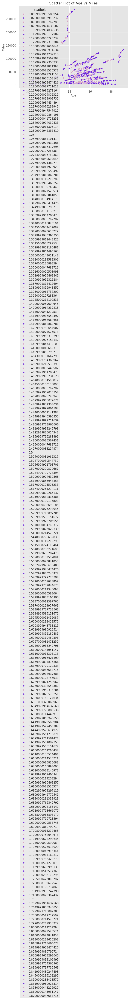

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

# Scatter plot for 'Age' vs 'Miles'
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='age', y='miles', hue='seatbelt', palette=['#D5A6C4', '#6D28D9'])
plt.title("Scatter Plot of Age vs Miles")
plt.xlabel("Age")
plt.ylabel("Miles")
plt.legend(title="seatbelt")
plt.show()

## 9.5 3D Scatter Plot

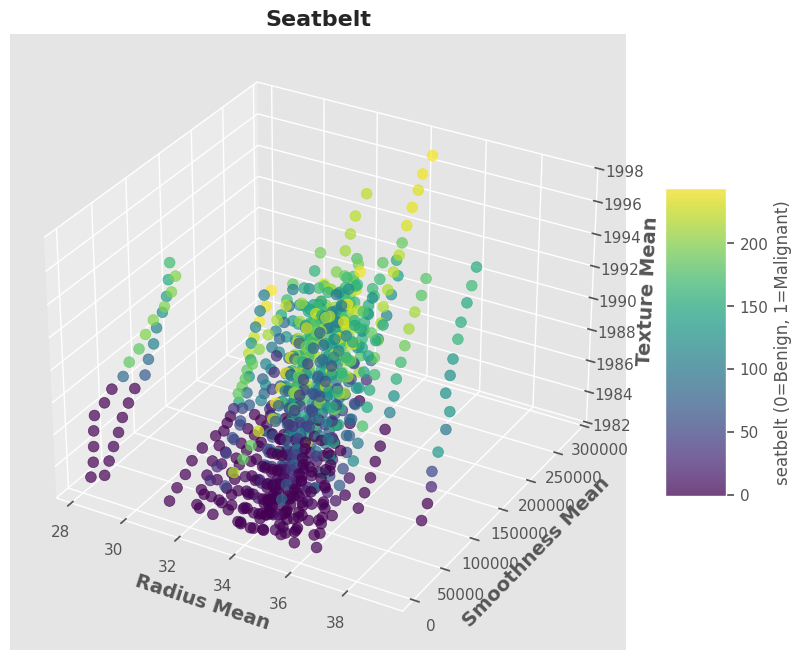

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Ensure 'seatbelt' is a categorical type
df['seatbelt'] = df['seatbelt'].astype('category')

# Create the 3D scatter plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(
    df['age'],
    df['miles'],
    df['year'],
    c=df['seatbelt'].cat.codes,  # Use the categorical codes
    s=60,
    alpha=0.7,
    cmap='viridis'  # Optional: adds a colormap
)

# Set labels
ax.set_xlabel('Radius Mean', fontsize=14, fontweight='bold')
ax.set_ylabel('Smoothness Mean', fontsize=14, fontweight='bold')
ax.set_zlabel('Texture Mean', fontsize=14, fontweight='bold')  # Increase fontsize for better visibility
ax.set_title('Seatbelt', fontsize=16, fontweight='bold')

# Optional: add a color bar
cbar = fig.colorbar(scatter, ax=ax, shrink=0.5, aspect=5)
cbar.set_label('seatbelt (0=Benign, 1=Malignant)', fontsize=12)

plt.show()

## 9.6 2D Box Plot

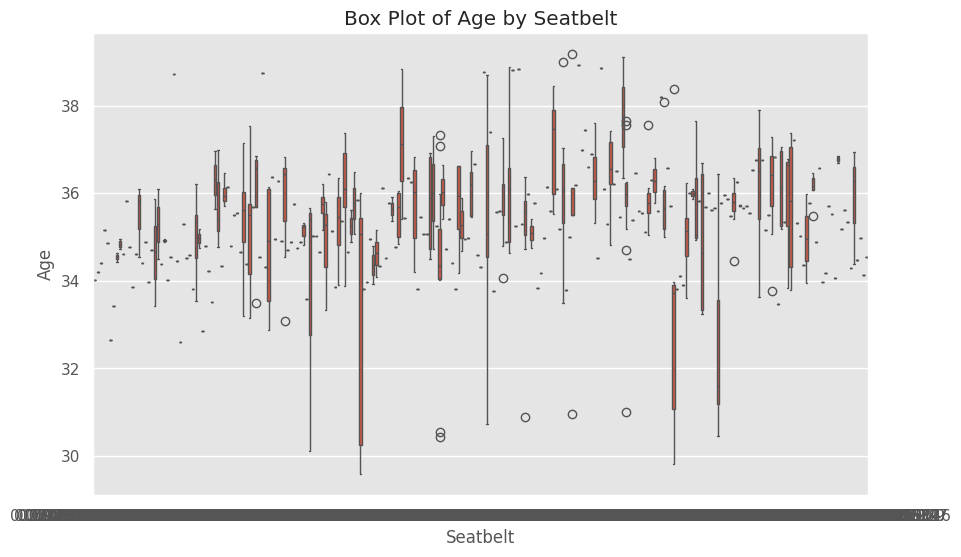

In [36]:
# Box plot of radius_mean by diagnosis
plt.figure(figsize=(10, 6))
sns.boxplot(x='seatbelt', y='age', data=df)
plt.title("Box Plot of Age by Seatbelt")
plt.xlabel("Seatbelt")
plt.ylabel("Age")
plt.show()

## 9.7 Customize the 3D Scatter Plot (Color, Shape, Bars)

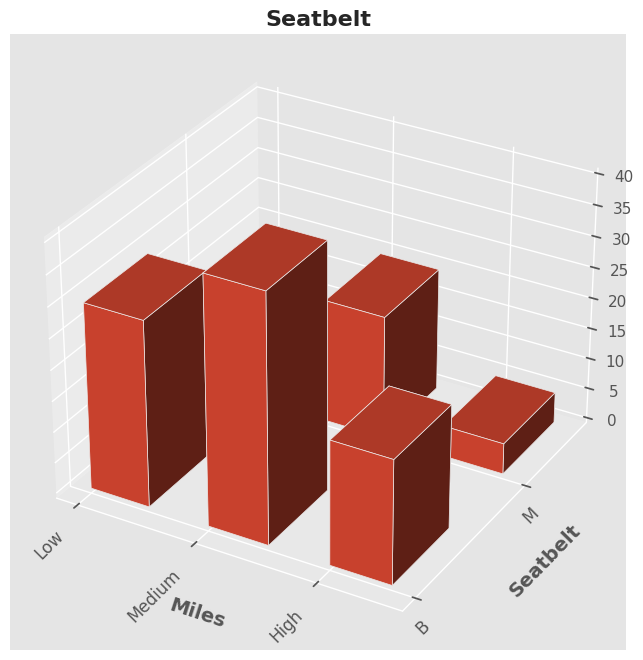

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# For example purposes only:
smoothness_categories = ['Low', 'Medium', 'High']
diagnoses = ['B', 'M']
values = [[30, 10], [40, 20], [20, 5]]  # Example counts for each category
contingency_table = pd.DataFrame(values, index=smoothness_categories, columns=diagnoses)

# Create the figure and 3D axis
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Prepare the data for 3D bar plot
x_pos = np.arange(len(contingency_table.index))  # Number of categories on x-axis
y_pos = np.arange(len(contingency_table.columns))  # Number of diagnoses on y-axis
z_pos = np.zeros((len(contingency_table.index), len(contingency_table.columns)))  # Base position for bars

# Bar heights
z_height = contingency_table.values.flatten()  # Flattened values for bar heights

# Width and depth for the bars
dx = 0.5  # Width of the bars
dy = 0.5  # Depth of the bars
dz = z_height  # Height of the bars

# Create the meshgrid for x and y positions
x_pos, y_pos = np.meshgrid(x_pos, y_pos, indexing='ij')

# Create the bars
ax.bar3d(x_pos.flatten(), y_pos.flatten(), z_pos.flatten(), dx, dy, dz, shade=True)

# Set axis labels and title with improved font size
ax.set_xlabel('Miles', fontsize=14, fontweight='bold', labelpad=10)
ax.set_ylabel('Seatbelt', fontsize=14, fontweight='bold', labelpad=10)
ax.set_zlabel('Frequency', fontsize=14, fontweight='bold', labelpad=10)
ax.set_title('Seatbelt', fontsize=16, fontweight='bold')

# Rotate the x and y axis labels for better visibility
ax.set_xticks(np.arange(len(contingency_table.index)))
ax.set_xticklabels(contingency_table.index, rotation=45, ha='right', fontsize=12)
ax.set_yticks(np.arange(len(contingency_table.columns)))
ax.set_yticklabels(contingency_table.columns, rotation=45, ha='right', fontsize=12)

plt.show()


## Module 5

## 10. K-Means Clustering

In [38]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

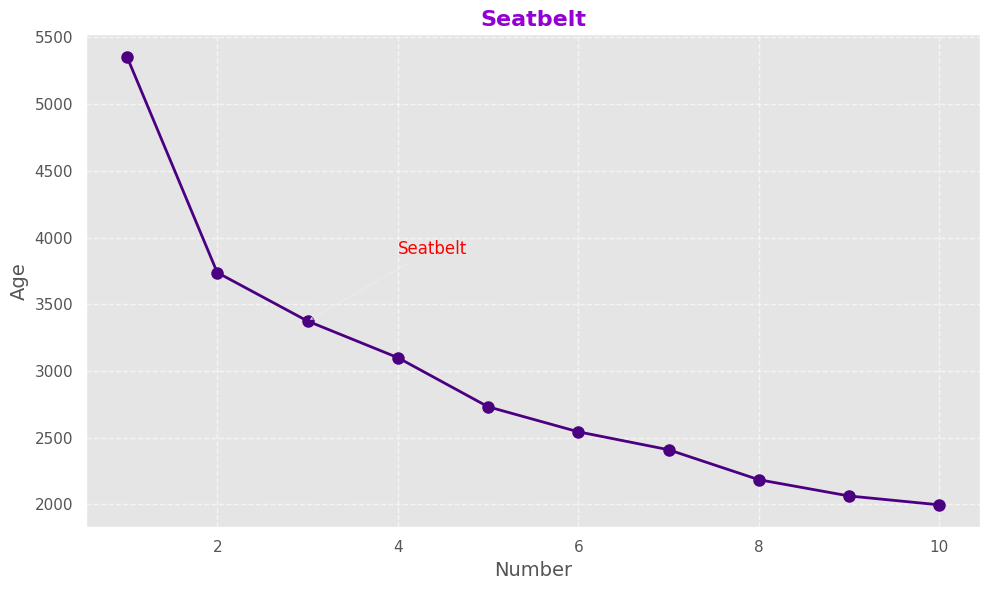

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler

# Load the dataset (assuming it's already loaded in your environment)
dataset = pd.read_csv('https://raw.githubusercontent.com/salemprakash/EDA/main/Data/USSeatBelts.csv')

# Select only numeric columns for clustering
# Assuming 'state' and 'rownames' are non-numeric columns
X = dataset.select_dtypes(include=np.number)

# Handle missing values before scaling (e.g., imputation or dropping rows)
# Option 1: Imputation (replace NaN with the mean of the column)
X = X.fillna(X.mean())

# Option 2: Drop rows with NaN values
# X = X.dropna()

# Standardize the data for better clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 2: Use the elbow method to find the optimal number of clusters
wcss = []  # Within-cluster sum of squares (WCSS)
for i in range(1, 11):  # Check from 1 to 10 clusters
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)  # Fit KMeans on the scaled data
    wcss.append(kmeans.inertia_)

# Plotting the WCSS to identify the elbow
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', color='indigo', linestyle='-', linewidth=2, markersize=8)

# Title and Labels
plt.title('Seatbelt', fontsize=16, fontweight='bold', color='darkviolet')
plt.xlabel('Number', fontsize=14)
plt.ylabel('Age', fontsize=14)

# Annotate the Elbow point (example, elbow at k=3, adjust based on your plot)
plt.annotate('Seatbelt', xy=(3, wcss[2]), xytext=(4, wcss[2] + 500),
             arrowprops=dict(facecolor='red', arrowstyle='->'), fontsize=12, color='red')

# Add gridlines for better readability
plt.grid(True, linestyle='--', alpha=0.6)

# Adjust layout for better spacing
plt.tight_layout()

# Show the plot
plt.show()

# 11. Hierarchical Clustering
## 11.1 Import Libraries and Load Dataset

In [40]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist, pdist
from scipy.cluster.hierarchy import linkage, dendrogram

# Load the breast cancer dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/USSeatBelts.csv"
df = pd.read_csv(url)

# Drop the 'Unnamed: 32' column and any rows with missing values
df = df.drop(columns=['seatbelt']).dropna()

# For clustering, let's use some of the 'mean' features as an example:
dataset = df[['rownames', 'year', 'fatalities', 'miles']]

In [41]:
# 1. Statistical summary of the selected features
print("Statistical Summary:")
print(dataset.describe())

Statistical Summary:
         rownames        year  fatalities          miles
count  765.000000   765.00000  765.000000     765.000000
mean   383.000000  1990.00000    0.021490   41447.734641
std    220.980768     4.32332    0.006171   43961.990037
min      1.000000  1983.00000    0.008327    3099.000000
25%    192.000000  1986.00000    0.017341   11401.000000
50%    383.000000  1990.00000    0.021199   30319.000000
75%    574.000000  1994.00000    0.024774   52312.000000
max    765.000000  1997.00000    0.045470  285612.000000


Sample of Euclidean Distance Matrix:
 [231.00432908 482.00829882 650.0138463  542.02952008 483.05175745
 529.06804906 621.0789003  663.09652418 483.16767304 560.17854316]


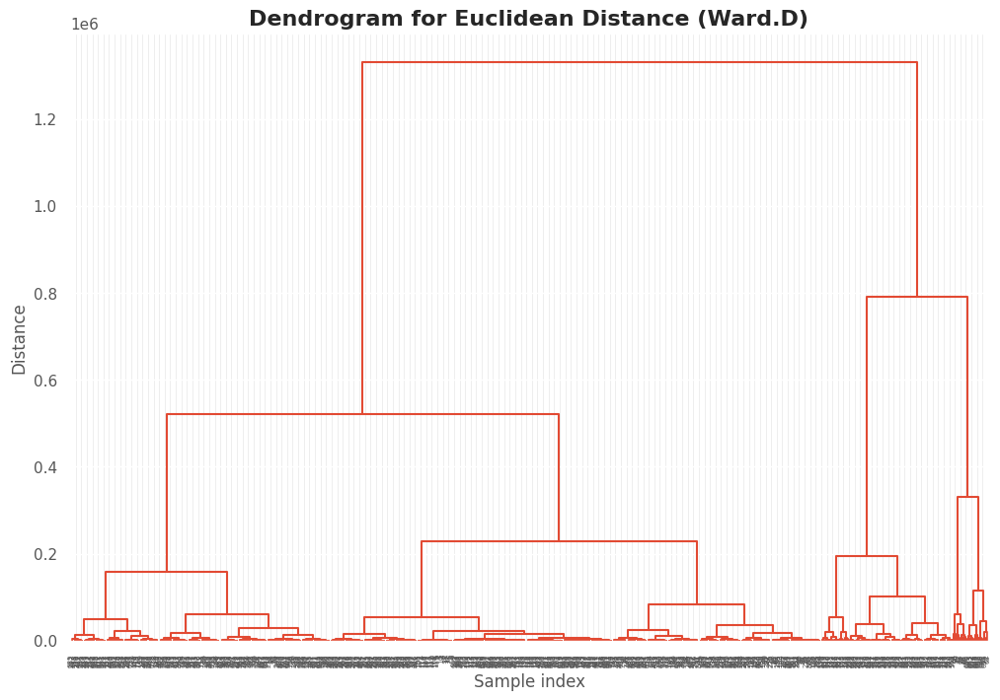

In [42]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

# 2. Compute the Euclidean distance matrix using pdist (pairwise distances)
euclidean_distances = pdist(dataset, metric='euclidean')
print("Sample of Euclidean Distance Matrix:\n", euclidean_distances[:10])


# 3. Dendrogram for Euclidean distance
linked = linkage(euclidean_distances, method='ward')

plt.figure(figsize=(12, 8))
plt.title('Dendrogram for Euclidean Distance (Ward.D)', fontsize=16, fontweight='bold')
plt.xlabel('Sample index', fontsize=12)
plt.ylabel('Distance', fontsize=12)

dendrogram(linked, color_threshold=0)

plt.gcf().set_facecolor('white')

plt.show()

Sample of Manhattan Distance Matrix:
 [233.00733314 486.01159653 656.01946984 550.02518227 493.01941561
 541.02305895 635.02004014 679.01955132 501.01655177 580.01455204]


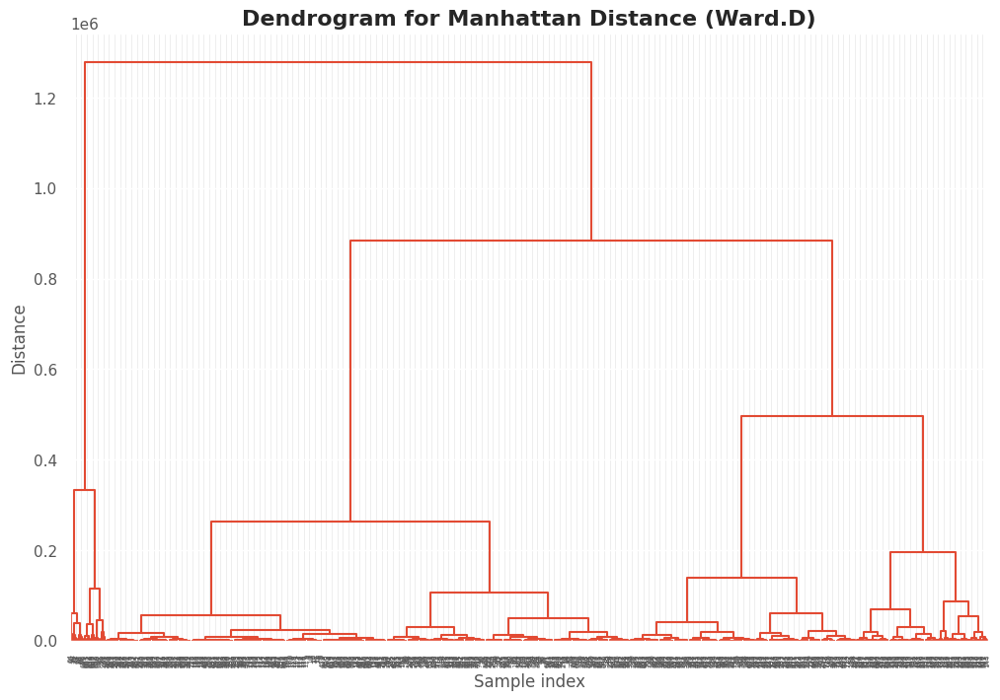

In [43]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

# 4. Compute the Manhattan distance matrix using pdist
manhattan_distances = pdist(dataset, metric='cityblock')
print("Sample of Manhattan Distance Matrix:\n", manhattan_distances[:10])

# 5. Dendrogram for Manhattan distance
linked_manhattan = linkage(manhattan_distances, method='ward')

plt.figure(figsize=(12, 8))
plt.title('Dendrogram for Manhattan Distance (Ward.D)', fontsize=16, fontweight='bold')
plt.xlabel('Sample index', fontsize=12)  # X-axis label
plt.ylabel('Distance', fontsize=12)  # Y-axis label

# Customize the appearance of the dendrogram
dendrogram(linked_manhattan, color_threshold=0)

plt.gcf().set_facecolor('white')

# Show the plot
plt.show()

Sample of Maximum Distance Matrix (Chebyshev):
 [231. 482. 650. 542. 483. 529. 621. 663. 483. 560.]


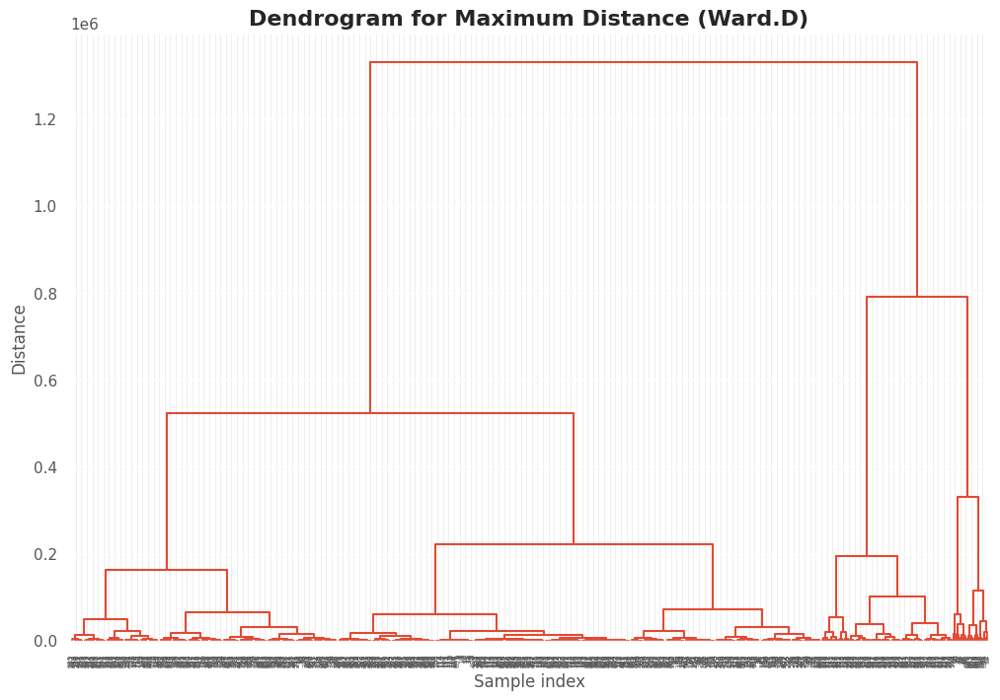

In [44]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

# 6. Compute the Maximum distance matrix using pdist (Chebyshev)
maximum_distances = pdist(dataset, metric='chebyshev')
print("Sample of Maximum Distance Matrix (Chebyshev):\n", maximum_distances[:10])


# 7. Dendrogram for Maximum distance (Chebyshev distance)
linked_maximum = linkage(maximum_distances, method='ward')

# Set up the plot
plt.figure(figsize=(12, 8))
plt.title('Dendrogram for Maximum Distance (Ward.D)', fontsize=16, fontweight='bold')
plt.xlabel('Sample index', fontsize=12)  # X-axis label
plt.ylabel('Distance', fontsize=12)  # Y-axis label

dendrogram(linked_maximum, color_threshold=0)

plt.gcf().set_facecolor('white')

plt.show()

Sample of Canberra Distance Matrix:
 [0.45625945 0.71663325 0.96766108 1.13486276 1.0603076  1.17242882
 1.15336392 1.17201735 1.1149383  1.10739395]


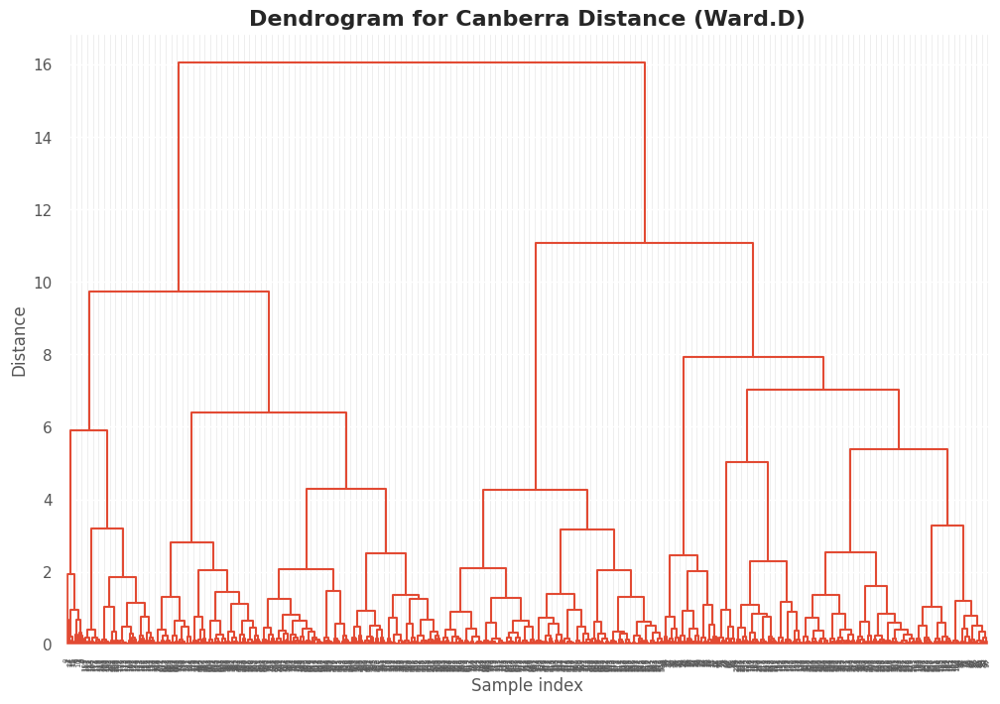

In [45]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

# 8. Compute the Canberra distance matrix using pdist
canberra_distances = pdist(dataset, metric='canberra')
print("Sample of Canberra Distance Matrix:\n", canberra_distances[:10])


# 9. Dendrogram for Canberra distance
linked_canberra = linkage(canberra_distances, method='ward')

# Set up the plot
plt.figure(figsize=(12, 8))
plt.title('Dendrogram for Canberra Distance (Ward.D)', fontsize=16, fontweight='bold')
plt.xlabel('Sample index', fontsize=12)
plt.ylabel('Distance', fontsize=12)

dendrogram(linked_canberra, color_threshold=0)

plt.gcf().set_facecolor('white')

plt.show()

Sample of Minkowski Distance Matrix (p=3):
 [231.00001249 482.00002296 650.0000426  542.00014524 483.00035721
 529.00051458 621.00059295 663.00077652 483.00208324 560.00212584]


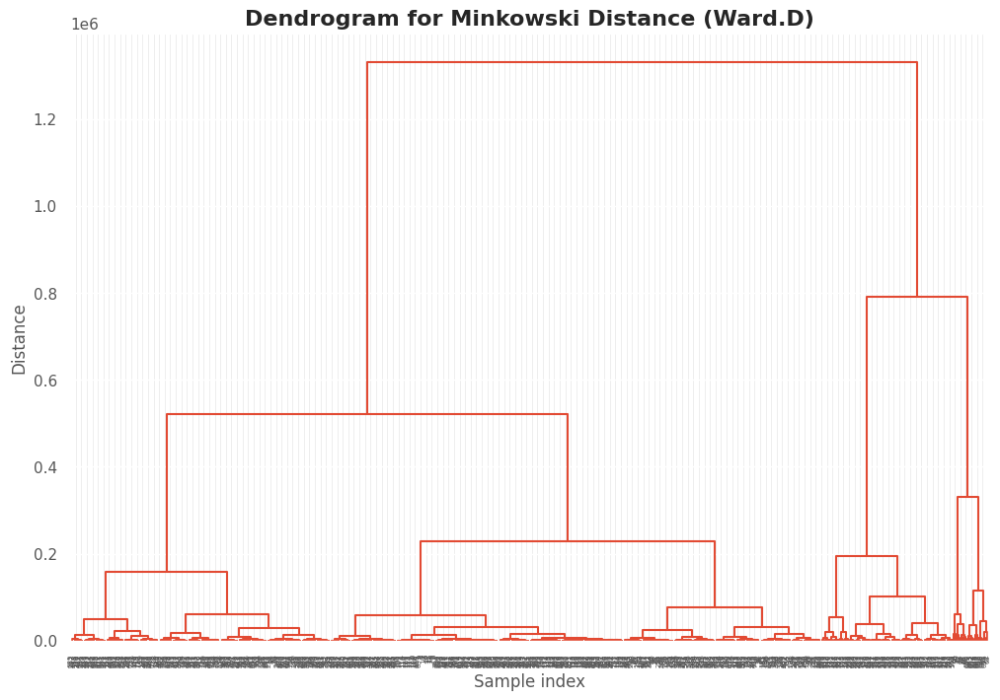

In [46]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

# 12. Compute the Minkowski distance matrix using pdist
# For Minkowski, we will set p=3 as an example
minkowski_distances = pdist(dataset, metric='minkowski', p=3)
print("Sample of Minkowski Distance Matrix (p=3):\n", minkowski_distances[:10])


# 13. Dendrogram for Minkowski distance
linked_minkowski = linkage(minkowski_distances, method='ward')

plt.figure(figsize=(12, 8))
plt.title('Dendrogram for Minkowski Distance (Ward.D)', fontsize=16, fontweight='bold')
plt.xlabel('Sample index', fontsize=12)
plt.ylabel('Distance', fontsize=12)

dendrogram(linked_minkowski, color_threshold=0)

plt.gcf().set_facecolor('white')

plt.show()

# Module 6
## Principle Compenent Analysis
## Step 1: Install and load necessary libraries

In [47]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

## Step 2: Load the Dataset

In [48]:
# Load the dataset
url = 'https://raw.githubusercontent.com/salemprakash/EDA/main/Data/USSeatBelts.csv'
df = pd.read_csv(url)

# View the first few rows of the dataset
df.head()

,rownames,state,year,miles,fatalities,seatbelt,speed65,speed70,drinkage,alcohol,income,age,enforce
0,1,AK,1983,3358,0.044669,NaN,no,no,yes,no,17973,28.234966,no
1,2,AK,1984,3589,0.037336,NaN,no,no,yes,no,18093,28.343542,no
2,3,AK,1985,3840,0.033073,NaN,no,no,yes,no,18925,28.372816,no
3,4,AK,1986,4008,0.025200,NaN,no,no,yes,no,18466,28.396652,no
4,5,AK,1987,3900,0.019487,NaN,no,no,yes,no,18021,28.453251,no


## Step 3: Perform PCA on Numeric Columns

In [49]:
# Drop non-numeric columns including 'state' and any other non-numeric columns
df_numeric = df.select_dtypes(include=np.number)

# Handle missing values before scaling (e.g., imputation or dropping rows)
# Option 1: Imputation (replace NaN with the mean of the column)
df_numeric = df_numeric.fillna(df_numeric.mean())

# Option 2: Drop rows with NaN values
# df_numeric = df_numeric.dropna()

# Standardize the data for better clustering
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df_numeric)

# Perform PCA
pca = PCA()
pca.fit(data_scaled)

# Display the explained variance ratio for each component
explained_variance_ratio = pca.explained_variance_ratio_
explained_variance_ratio

array([0.42435988, 0.15242033, 0.13706926, 0.1231208 , 0.0868533 ,
       0.05343697, 0.02273944])

## Step 4: Print PCA Results (Eigenvalues and Component Loadings)

In [50]:
# Eigenvalues (explained variance ratio)
explained_variance_ratio = pca.explained_variance_ratio_
print("Explained Variance Ratio (Eigenvalues):\n", explained_variance_ratio)

# Component loadings (coefficients of the components)
component_loadings = pca.components_
print("\nComponent Loadings (coefficients):\n", component_loadings)

Explained Variance Ratio (Eigenvalues):
 [0.42435988 0.15242033 0.13706926 0.1231208  0.0868533  0.05343697
 0.02273944]

Component Loadings (coefficients):
 [[-0.00943093  0.49927279  0.17183903 -0.45700012  0.35462135  0.53351016
   0.31917172]
 [ 0.8194193   0.07656296 -0.50653755 -0.15662765 -0.07669114 -0.07968707
   0.17130692]
 [ 0.49530212 -0.02221554  0.55756942  0.1002678   0.46303584 -0.09831802
  -0.45735804]
 [ 0.2145938  -0.205551    0.62312553 -0.14025069 -0.47708158 -0.11440451
   0.51288146]
 [-0.01165935 -0.03212676 -0.03627069  0.56550558  0.50740976 -0.18332135
   0.62181061]
 [ 0.10349516  0.69623532  0.11134704  0.55427507 -0.40283918  0.11501862
  -0.09704344]
 [ 0.16199135 -0.46512826 -0.03175304  0.33147757 -0.08129629  0.7996412
  -0.02222   ]]


## Step 5: Visualize PCA Components Using plot() and biplot()

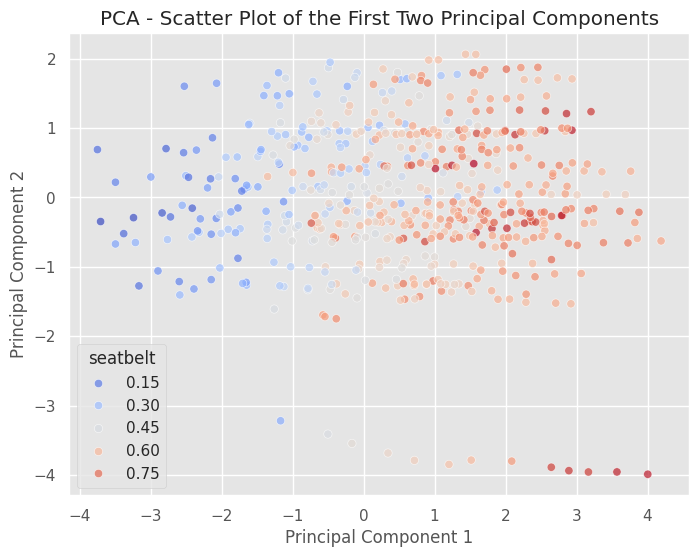

In [51]:
# Get the first two principal components
pc_df = pd.DataFrame(pca.transform(data_scaled), columns=[f"PC{i+1}" for i in range(pca.n_components_)])

# Create a scatter plot with different colors for the data points
plt.figure(figsize=(8, 6))

# Scatter plot with colors based on the index (you can replace this with any other feature)
sns.scatterplot(x=pc_df['PC1'], y=pc_df['PC2'], hue=df['seatbelt'], palette='coolwarm', alpha=0.7)

# Add titles and labels
plt.title('PCA - Scatter Plot of the First Two Principal Components')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

# Show a grid for better readability
plt.grid(True)

# Display the legend to distinguish the seatbelt categories
plt.legend(title='seatbelt', loc='best')

# Show the plot
plt.show()

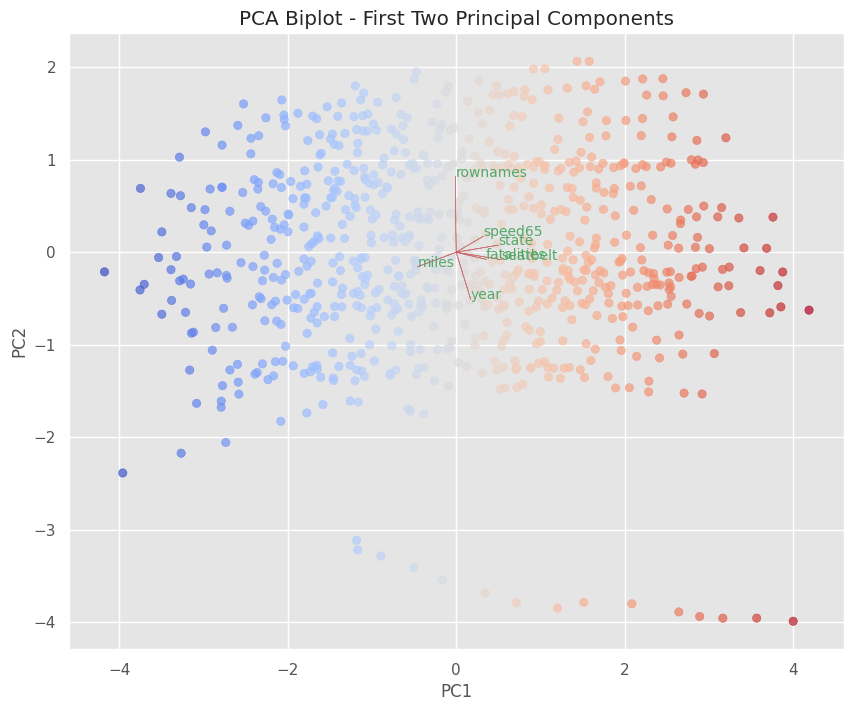

In [52]:
# Biplot
def biplot(score, coeff, labels=None, scale=1):
    xs = score[:, 0]
    ys = score[:, 1]

    # Create a figure for the biplot
    plt.figure(figsize=(10, 8))

    # Use a color map to differentiate points
    plt.scatter(xs, ys, alpha=0.7, c=xs, cmap='coolwarm')  # Color points based on PC1 values

    # Add arrows for the components
    for i in range(len(coeff)):
        plt.arrow(0, 0, coeff[i, 0] * scale, coeff[i, 1] * scale, color='r', alpha=0.7)

        # Add labels for the arrows (variables)
        if labels is None:
            plt.text(coeff[i, 0] * scale, coeff[i, 1] * scale, "Var" + str(i + 1), color='g')
        else:
            plt.text(coeff[i, 0] * scale, coeff[i, 1] * scale, labels[i], color='g')

    # Set axis labels and grid
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(True)

    # Set the title of the plot
    plt.title('PCA Biplot - First Two Principal Components')

    # Display the plot
    plt.show()

# Call the biplot function using the first two principal components
biplot(pc_df[['PC1', 'PC2']].values, np.transpose(pca.components_), labels=df.columns)

## Step 6: Create a Scree Plot to Determine the Optimal Number of Principal Components

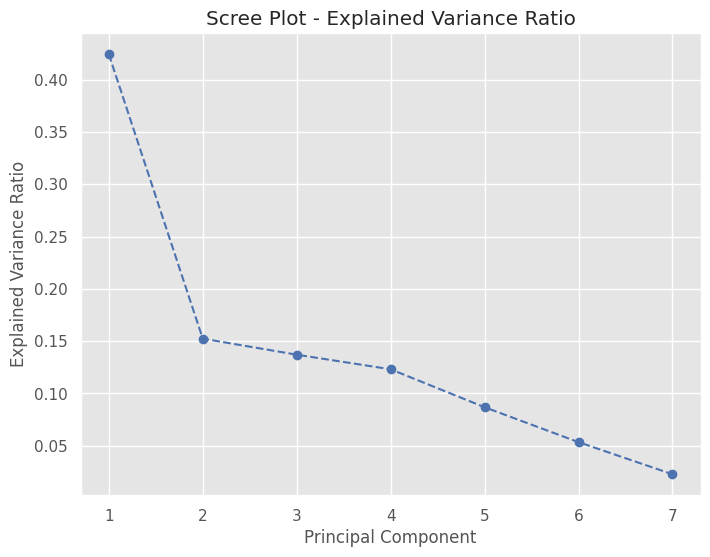

In [53]:
# Scree plot to visualize the explained variance ratio (Eigenvalues)
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker='o', linestyle='--', color='b')
plt.title('Scree Plot - Explained Variance Ratio')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.grid(True)
plt.show()

## Step 7: Select the Desired Number of Components (n_comp)

In [54]:
n_comp = 5  # Choose the number of components based on the scree plot
pca = PCA(n_components=n_comp)
data_pca = pca.fit_transform(data_scaled)

# Display the explained variance ratio of the selected components
print(f"Explained variance ratio for the first {n_comp} components: {pca.explained_variance_ratio_}")

Explained variance ratio for the first 5 components: [0.42435988 0.15242033 0.13706926 0.1231208  0.0868533 ]


## Step 8: Perform PCA with the Selected Components

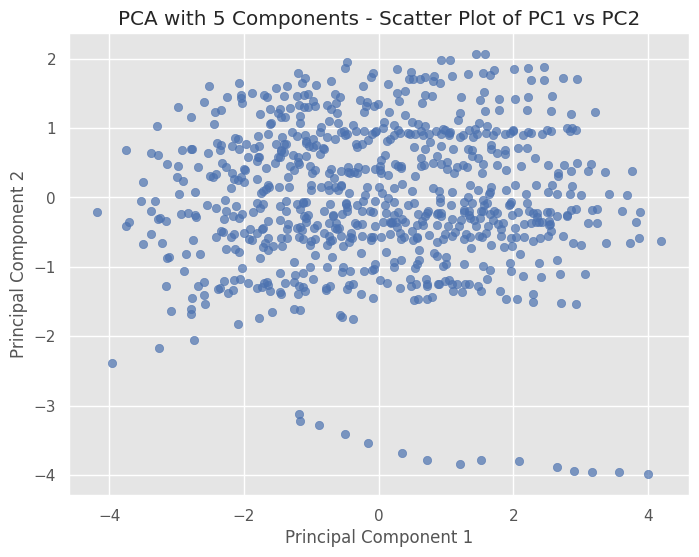

In [55]:
# Perform PCA with the selected number of components
pca = PCA(n_components=n_comp)
data_pca = pca.fit_transform(data_scaled)

# Visualize the transformed data (First two components)
pc_df = pd.DataFrame(data_pca, columns=[f"PC{i+1}" for i in range(n_comp)])
plt.figure(figsize=(8, 6))
plt.scatter(pc_df['PC1'], pc_df['PC2'], alpha=0.7, color='b')
plt.title(f'PCA with {n_comp} Components - Scatter Plot of PC1 vs PC2')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

## Step 9: Plot the Selected PCA Components

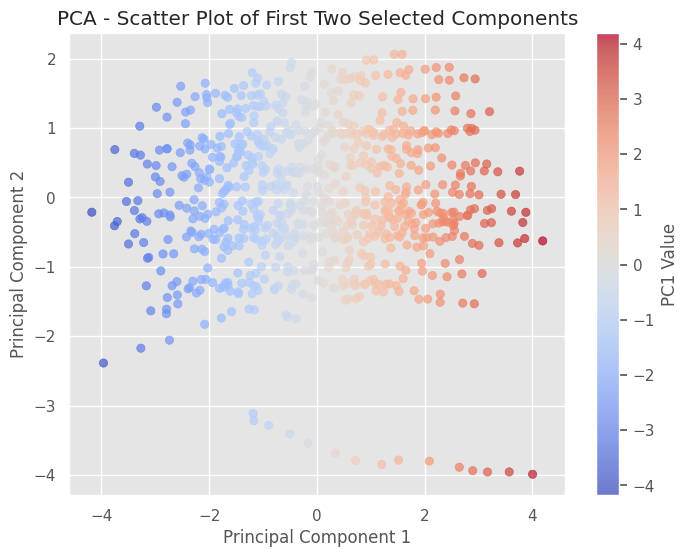

In [56]:
# Step 9: Plot the Selected PCA Components
# Plot the first two selected principal components
plt.figure(figsize=(8, 6))

# Use color based on the values of the first principal component (PC1)
plt.scatter(pc_df['PC1'], pc_df['PC2'], alpha=0.7, c=pc_df['PC1'], cmap='coolwarm')

# Add a color bar to indicate the color mapping
plt.colorbar(label='PC1 Value')

# Set plot titles and axis labels
plt.title('PCA - Scatter Plot of First Two Selected Components')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

# Add grid for better readability
plt.grid(True)

# Show the plot
plt.show()


## Step 10: Interpret the Results Using summary()

Explained Variance Ratio: [0.42435988 0.15242033 0.13706926 0.1231208  0.0868533 ]
Cumulative Explained Variance: [0.42435988 0.57678022 0.71384948 0.83697028 0.92382358]


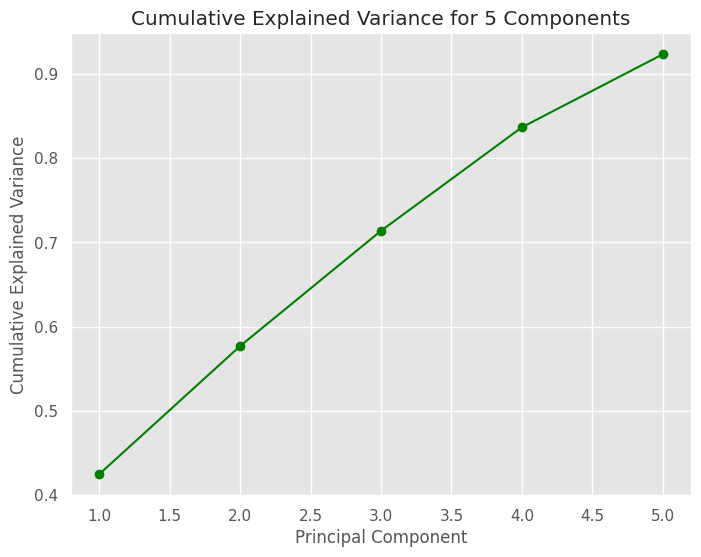

In [57]:
# Explained variance ratio and cumulative explained variance
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
print("Cumulative Explained Variance:", cumulative_variance)

# Summary of the PCA results
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='-', color='green')
plt.title(f'Cumulative Explained Variance for {n_comp} Components')
plt.xlabel('Principal Component')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()

# Module 7
## Step 1: Load Dataset

In [58]:
import pandas as pd

# Load the dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/USSeatBelts.csv"
df = pd.read_csv(url)

## Step 2: Data Cleaning and Preprocessing

In [59]:
df.fillna(df.median(numeric_only=True), inplace=True)  # Numeric columns
for col in df.select_dtypes(include='object').columns:
    df[col].fillna(df[col].mode()[0], inplace=True)  # Categorical columns

if 'Unnamed: 32' in df.columns:
    df.drop(columns=['Unnamed: 32'], inplace=True)

## Step 3: Identify Relationships Between Features

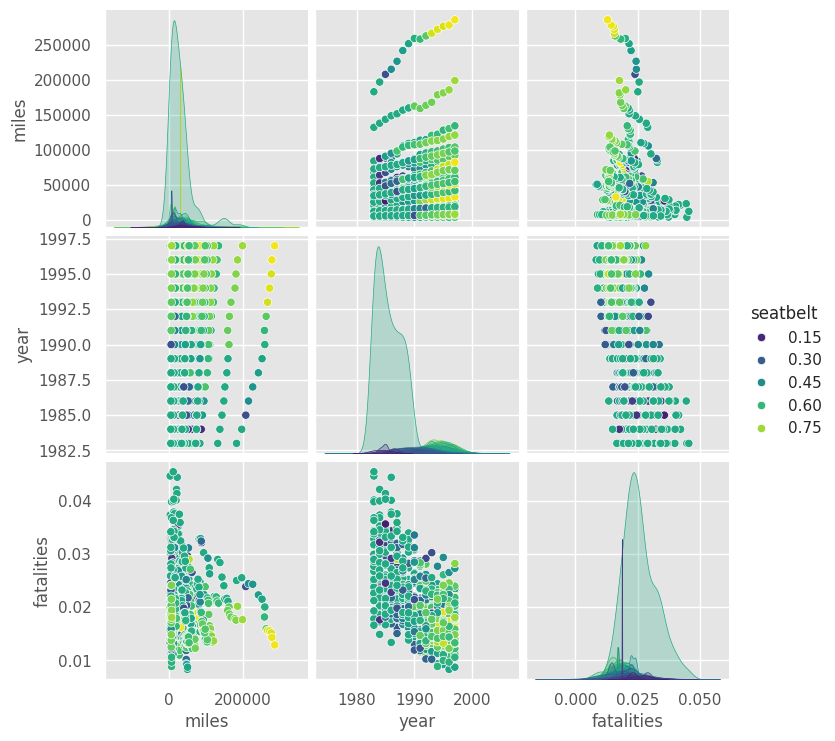

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt

# Replace with actual column names from your DataFrame 'df'
# For example, if your DataFrame has columns 'miles', 'seatbelt', 'year', and 'fatalities':
sns.pairplot(df[['miles', 'seatbelt', 'year', 'fatalities']], hue='seatbelt', palette="viridis")
plt.show()

## Step 4: Split the Dataset into Training and Test Sets

In [61]:
from sklearn.model_selection import train_test_split

# Independent (X) and Dependent (Y) Variables
# Assuming 'miles' is your independent variable and 'fatalities' is your dependent variable
# Replace with the actual column names if different
X = df[['miles']]  # Independent variable
y = df['fatalities']   # Dependent variable


# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=1/3, random_state=42)

## Step 5: Simple Linear Regression

In [62]:
from sklearn.linear_model import LinearRegression

# Fit the model
reg1 = LinearRegression()
reg1.fit(X_train, y_train)

LinearRegression()

In [63]:
# Print coefficients and intercept
print(f"Coefficient: {reg1.coef_[0]}")
print(f"Intercept: {reg1.intercept_}")

Coefficient: -2.5558333163423284e-08
Intercept: 0.022507507402334155


In [64]:
y_pred = reg1.predict(X_test)

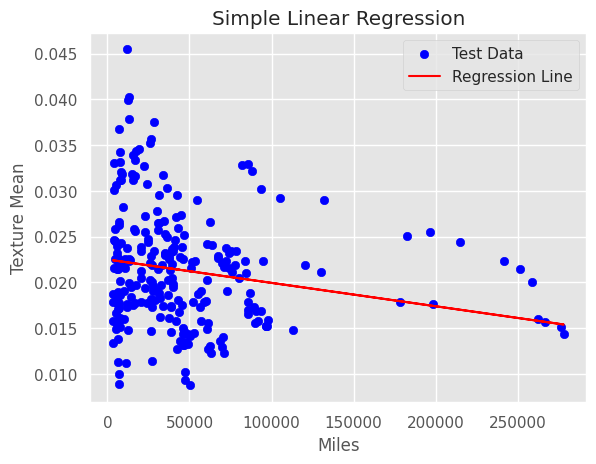

In [65]:
# Scatter plot with regression line
plt.scatter(X_test, y_test, color='blue', label='Test Data')
plt.plot(X_test, y_pred, color='red', label='Regression Line')
plt.xlabel("Miles")
plt.ylabel("Texture Mean")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

## Step 6: Multiple Linear Regression with Log Transformation

In [66]:
import numpy as np

# Apply log transformation to a variable, e.g., 'miles'
df['log_miles'] = np.log(df['miles'])

# Independent variables and dependent variable
X_multi = df[['year', 'fatalities', 'log_miles']]  # Replaced with relevant columns
y_multi = df['seatbelt']  # Replace with your dependent variable

# Split dataset
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(X_multi, y_multi, test_size=1/3, random_state=42)

# Fit model
reg2 = LinearRegression()
reg2.fit(X_train_multi, y_train_multi)

LinearRegression()

In [67]:
# Predictions
y_pred_multi = reg2.predict(X_test_multi)

# Residuals
residuals = y_test_multi - y_pred_multi
print("Residuals:\n", residuals)

Residuals:
 357    0.038821
259   -0.280449
751    0.113746
193    0.121264
333   -0.009902
         ...   
432   -0.181428
302   -0.272956
545   -0.180236
609   -0.029031
632    0.089496
Name: seatbelt, Length: 255, dtype: float64


In [68]:
pred_residuals = pd.DataFrame({
    'Predicted': y_pred_multi,
    'Residuals': residuals
})
print(pred_residuals.head())


     Predicted  Residuals
357   0.611179   0.038821
259   0.490449  -0.280449
751   0.436254   0.113746
193   0.628736   0.121264
333   0.472902  -0.009902


## Step 7: Visualize with ggplot or qqPlot

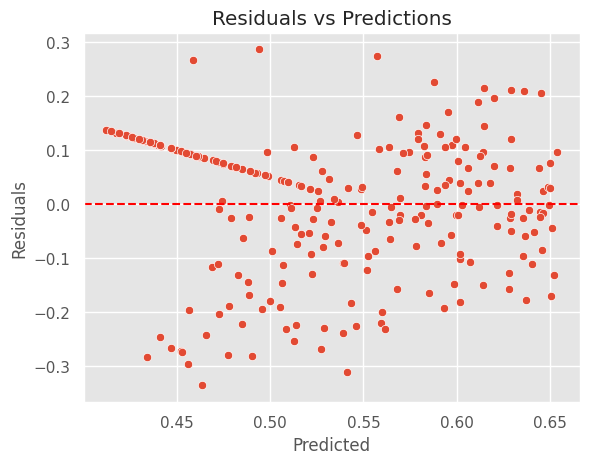

In [69]:
sns.scatterplot(x=pred_residuals['Predicted'], y=pred_residuals['Residuals'])
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residuals vs Predictions")
plt.show()


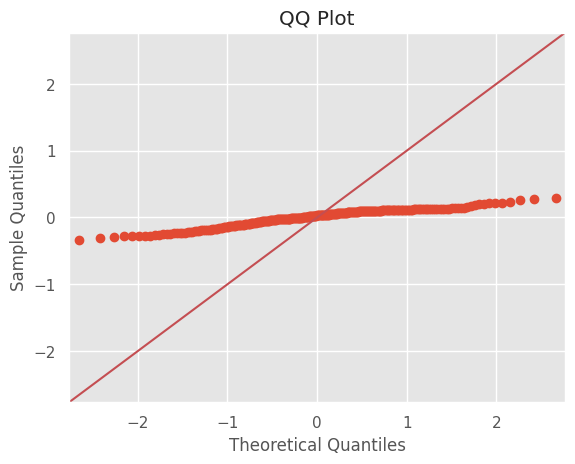

In [70]:
import statsmodels.api as sm

sm.qqplot(residuals, line='45')
plt.title("QQ Plot")
plt.show()

## Step 8: Logistic Regression Implementation:

In [71]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [72]:
# Assign X and y
X = df[['miles']]  # Independent variable - Changed 'radius_mean' to 'miles'
y = df['fatalities']      # Dependent variable - Changed 'diagnosis' to 'fatalities'

# Split the dataset into training and testing sets (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [73]:
# Assign X and y
X = df[['miles']]  # Independent variable - Changed 'radius_mean' to 'miles'
# Convert 'fatalities' to categorical using a threshold or binning strategy
# Here's an example using a threshold (you might need to adjust based on your data)
threshold = df['fatalities'].median()  # Using median as a threshold
y = pd.Series(np.where(df['fatalities'] > threshold, 1, 0))  # 1 if above threshold, 0 otherwise

# Split the dataset into training and testing sets (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Create logistic regression model
log_reg = LogisticRegression()

# Fit the model to the training data
log_reg.fit(X_train, y_train)

LogisticRegression()

In [74]:
# Predicting the Test set results
y_pred = log_reg.predict(X_test)

In [75]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Classification Report
cr = classification_report(y_test, y_pred)
print("Classification Report:")
print(cr)


Confusion Matrix:
[[53 66]
 [31 80]]
Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.45      0.52       119
           1       0.55      0.72      0.62       111

    accuracy                           0.58       230
   macro avg       0.59      0.58      0.57       230
weighted avg       0.59      0.58      0.57       230



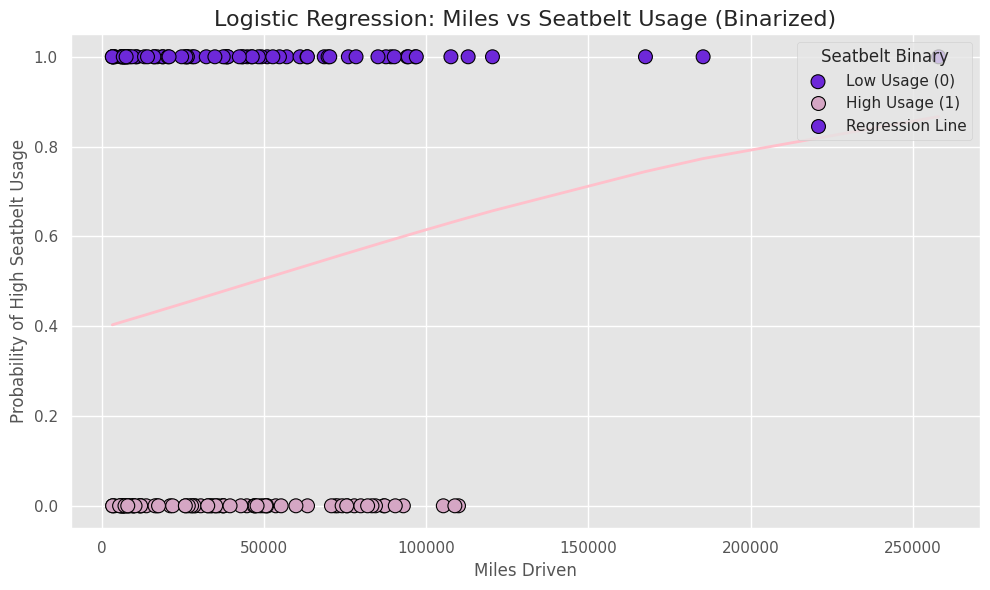

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# === Load dataset ===
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/USSeatBelts.csv"
df = pd.read_csv(url)

# === Check for required columns ===
# Changed 'Miles' to 'miles' and 'Seatbelts' to 'seatbelt'
assert 'miles' in df.columns and 'seatbelt' in df.columns, "Required columns not found"

# === Drop NaNs in both relevant columns ===
# Changed 'Miles' to 'miles' and 'Seatbelts' to 'seatbelt'
df = df[['miles', 'seatbelt']].dropna()

# === Binarize 'seatbelt' based on median usage ===
# Changed 'Seatbelts' to 'seatbelt'
median_value = df['seatbelt'].median()
df['seatbelt_binary'] = (df['seatbelt'] > median_value).astype(int)

# === Define X and y ===
X = df[['miles']]
y = df['seatbelt_binary']

# === Train-test split ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# === Train Logistic Regression model ===
model = LogisticRegression()
model.fit(X_train, y_train)

# === Predict probabilities ===
predicted_probabilities = model.predict_proba(X_test)[:, 1]

# === Plotting ===
plt.figure(figsize=(10, 6))

# Scatter plot of actual labels
sns.scatterplot(
    x=X_test['miles'],
    y=y_test,
    hue=y_test,
    palette=["#D5A6C4", "#6D28D9"],
    s=100,
    edgecolor="black",
    zorder=2
)

# Sort by miles for smooth curve
sorted_indices = X_test['miles'].argsort()
sorted_X_test = X_test.iloc[sorted_indices]
sorted_probabilities = predicted_probabilities[sorted_indices]

# Logistic regression curve
plt.plot(
    sorted_X_test['miles'],
    sorted_probabilities,
    color='pink',
    linewidth=2,
    zorder=1
)

# Labels and title
plt.title('Logistic Regression: Miles vs Seatbelt Usage (Binarized)', fontsize=16)
plt.xlabel('Miles Driven', fontsize=12)
plt.ylabel('Probability of High Seatbelt Usage', fontsize=12)

# Custom legend
plt.legend(
    title="Seatbelt Binary",
    labels=['Low Usage (0)', 'High Usage (1)', 'Regression Line'],
    loc='upper right'
)

plt.tight_layout()
plt.show()